# IV drip monitor: drop detector training (YOLOv8n, experiments A and B)

**Owner:** Jana · **Output:** `drops.pt` for Rawan, plus training metrics and plots for Raghad.

## Result in short
| | A (default augmentation) | B (stronger translate, scale, rotation) |
|---|---|---|
| Val recall | 0.987 | 0.986 |
| Val mAP50 | 0.994 | 0.994 |
| Empty val frames with a false detection at conf 0.25 | 8 of 35 | 35 of 35 |
| Conf needed for (almost) no false detections | 0.4 (recall 0.985) | 0.6 (recall 0.972) |

**Selected: model A at conf 0.4.** Both models find the drops equally well, but B also fires on empty drip tips. A reaches almost zero false detections at a lower threshold and keeps a higher recall there. Section 11 applies this rule to the full threshold sweep.

## What this notebook does
1. Copies `MyDrive/iv_drip/dataset.zip` from Drive and checks it: split counts, no video leakage, box sizes.
2. Previews both augmentation settings on real training images.
3. Trains **A** (Ultralytics default augmentation) and **B** (translate 0.1 → 0.3, scale 0.5 → 0.3, degrees 0 → 5, close_mosaic 10 → 15), 80 epochs max at 640, patience 15, seed 42.
4. Compares them on **val only**: Ultralytics metrics, a confidence sweep, recall per video, recall on tiny drops, false detections on empty frames, and recall under a random spatial shift.
5. Picks the model and its confidence threshold, then exports `drops.pt`, the metrics and the plots to Drive.
6. A final cell, off by default, computes the **test** metrics for Raghad. Run it **once**, after the model is final.

**How to run.** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all.
Training runs are saved on Drive in `MyDrive/iv_drip/runs/`. Finished runs are skipped, so running everything again does **not** retrain. An unfinished run resumes from its last epoch.

Training time on a T4: A 142 min (67 epochs, early stop), B 118 min (56 epochs, early stop).

In [2]:
# 1. GPU check and install. The version is pinned so that Rawan loads drops.pt with the same Ultralytics version.
!nvidia-smi -L || echo "No GPU found: Runtime > Change runtime type > T4 GPU"
%pip install -q "ultralytics==8.4.218"

GPU 0: Tesla T4 (UUID: GPU-5d3d29b5-98fe-3f5a-4716-907daac7eb37)


## 2. Configuration
Everything you might want to change is in this cell.

In [3]:
import os, sys, re, json, time, shutil, random, zipfile, platform
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2, yaml, torch
from PIL import Image
from IPython.display import display, Image as IPImage

import ultralytics
from ultralytics import YOLO

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = Path("/kaggle/working").exists()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

if IN_KAGGLE:
    DRIVE_DIR = Path("/kaggle/working/iv_drip")
    WORK = Path("/kaggle/temp")
else:
    DRIVE_DIR = Path("/content/drive/MyDrive/iv_drip")  # persistent (Drive)
    WORK = Path("/content")                              # fast local disk

DATASET_ZIP = DRIVE_DIR / "dataset.zip"
DATA_DIR = WORK / "dataset"
DATA_YAML = DATA_DIR / "data.yaml"
RUNS_DIR = DRIVE_DIR / "runs"                 # training runs live on Drive, so a disconnect loses nothing
OUT_DIR = DRIVE_DIR / "training_outputs"      # everything for Rawan and Raghad
SHIFT_MIN, SHIFT_MAX = 0.10, 0.25   # random spatial shift: each axis moves 10-25% of the image, random sign
SHIFTED_VAL = WORK / f"val_shifted_{int(SHIFT_MIN * 100)}_{int(SHIFT_MAX * 100)}"   # val images moved (position-sensitivity check)

# Training settings (from the plan)
SEED = 42
EPOCHS = 80
IMGSZ = 640
PATIENCE = 15
BATCH = 32            # fits a T4 easily for YOLOv8n at 640; lower to 16 if you get CUDA out-of-memory
WORKERS = min(8, os.cpu_count() or 2)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
BASE_WEIGHTS = "yolov8n.pt"

# Evaluation settings
EVAL_CONF = 0.25      # fixed confidence used to compare A and B (Ultralytics' default predict threshold)
IOU_MATCH = 0.5       # a prediction counts as a hit if IoU >= 0.5 with a labeled drop (same as mAP50)
IOU_LOOSE = 0.3       # also reported: tiny boxes lose IoU fast for a few pixels of offset
TINY_AREA = 10 * 12   # a drop is "tiny" if its box is <= 120 px^2 at imgsz 640 (your EDA's smallest 10%)
EXPECTED = {"train": 6442, "val": 1681, "test": 1345}   # image counts from prepare_data.py

for d in (DRIVE_DIR, RUNS_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

COLORS = {"A": "#257de0", "B": "#f47230"}   # fixed colour per experiment in every plot
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e6e6",
                     "axes.edgecolor": "#999999", "axes.spines.top": False, "axes.spines.right": False})

GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"
print(f"Ultralytics {ultralytics.__version__} | torch {torch.__version__} | {GPU_NAME} | device={DEVICE}")
if DEVICE == "cpu":
    print("WARNING: no GPU. Training 80 epochs on CPU will take far too long.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
Ultralytics 8.4.218 | torch 2.14.1+cu130 | Tesla T4 | device=0


## 3. Get the dataset onto local disk
Reading thousands of small images from Drive during training is very slow, so the zip is copied to the Colab disk and unzipped there.
`data.yaml` is rewritten with absolute paths, so it works whatever folder layout the zip has.

In [4]:
def find_dataset_source():
    """Return ('zip', path) or ('dir', path_of_folder_with_data.yaml)."""
    if DATASET_ZIP.exists():
        return "zip", DATASET_ZIP
    if IN_KAGGLE:
        zips = sorted(Path("/kaggle/input").rglob("dataset.zip"))
        if zips:
            return "zip", zips[0]
        yamls = sorted(Path("/kaggle/input").rglob("data.yaml"), key=lambda p: len(p.parts))
        if yamls:
            return "dir", yamls[0].parent
    raise FileNotFoundError(f"dataset.zip not found at {DATASET_ZIP}. Check the Drive folder name.")


def resolve_split(value, root):
    """Turn a data.yaml split entry (relative, Roboflow '../x', or absolute) into an existing absolute path."""
    if value is None:
        return None
    cands = [Path(value), root / value, root / re.sub(r"^(\.\./)+", "", str(value))]
    if "valid" in str(value):
        cands.append(root / re.sub(r"^(\.\./)+", "", str(value)).replace("valid", "val"))
    for c in cands:
        if c.exists():
            return str(c.resolve())
    raise FileNotFoundError(f"Split path '{value}' from data.yaml not found under {root}")


def prepare_dataset():
    if (DATA_DIR / ".ready").exists():
        print("Dataset already prepared at", DATA_DIR)
        return
    kind, src = find_dataset_source()
    tmp = WORK / "_unzip"
    shutil.rmtree(tmp, ignore_errors=True); shutil.rmtree(DATA_DIR, ignore_errors=True)
    t0 = time.time()
    if kind == "zip":
        local_zip = WORK / "dataset.zip"
        shutil.copy(src, local_zip)
        with zipfile.ZipFile(local_zip) as z:
            z.extractall(tmp)
        local_zip.unlink()
    else:
        shutil.copytree(src, tmp)
    yamls = sorted((p for p in tmp.rglob("data.yaml") if "__MACOSX" not in p.parts), key=lambda p: len(p.parts))
    if not yamls:
        raise FileNotFoundError("No data.yaml inside the dataset")
    shutil.move(str(yamls[0].parent), str(DATA_DIR))
    shutil.rmtree(tmp, ignore_errors=True)

    cfg = yaml.safe_load(DATA_YAML.read_text())
    cfg["path"] = str(DATA_DIR)
    for k in ("train", "val", "test"):
        if k in cfg:
            cfg[k] = resolve_split(cfg[k], DATA_DIR)
    assert cfg.get("nc") == 1 and list(cfg.get("names", [])) == ["drop"], f"unexpected classes: {cfg.get('names')}"
    DATA_YAML.write_text(yaml.safe_dump(cfg, sort_keys=False))
    (DATA_DIR / ".ready").touch()
    print(f"Prepared in {time.time() - t0:.0f}s from {src}")


prepare_dataset()
DATA_CFG = yaml.safe_load(DATA_YAML.read_text())
print(yaml.safe_dump(DATA_CFG, sort_keys=False))

Prepared in 23s from /content/drive/MyDrive/iv_drip/dataset.zip
path: /content/dataset
train: /content/dataset/images/train
val: /content/dataset/images/val
test: /content/dataset/images/test
nc: 1
names:
- drop



## 4. Dataset sanity check
Confirms the image counts, that **no video appears in two splits**, and the drop size at imgsz 640.
The test split is only counted here; nothing else touches it until the final cell.

In [5]:
from ultralytics.data.utils import img2label_paths, IMG_FORMATS

# Two filename styles in this dataset, both mapped to the same id:
#   60P-3-_mp4-452_jpg.rf...                  -> 60P-3
#   20H1-60s-Made-with-Clipchamp_mp4-0_jpg... -> 20H-1
VIDEO_RE = re.compile(r"^(\d+)([HP])-?(\d+)")
EXPECTED_VIDEOS = {"train": 11, "val": 3, "test": 2}


def video_id(path):
    m = VIDEO_RE.match(Path(path).name)
    return f"{m.group(1)}{m.group(2)}-{m.group(3)}" if m else "unknown"


def list_images(d):
    return sorted(str(p) for p in Path(d).rglob("*") if p.suffix.lower().lstrip(".") in IMG_FORMATS)


def read_labels(img_path):
    """YOLO labels as an (n, 4) array of normalized xc, yc, w, h (class column dropped: one class)."""
    lp = Path(img2label_paths([img_path])[0])
    if not lp.exists():
        return np.zeros((0, 4))
    rows = [ln.split() for ln in lp.read_text().splitlines() if ln.strip()]
    return np.array([[float(v) for v in r[1:5]] for r in rows]).reshape(-1, 4)


SPLIT_FILES = {k: list_images(DATA_CFG[k]) for k in ("train", "val", "test") if k in DATA_CFG}
rows, videos = [], {}
for split, files in SPLIT_FILES.items():
    n_boxes = n_empty = 0
    for f in files:
        n = len(read_labels(f)); n_boxes += n; n_empty += (n == 0)
    videos[split] = sorted({video_id(f) for f in files})
    rows.append({"split": split, "images": len(files), "expected": EXPECTED.get(split), "boxes": n_boxes,
                 "empty frames": n_empty, "videos": len(videos[split]), "video ids": ", ".join(videos[split])})
summary = pd.DataFrame(rows)
display(summary)

for split, n in EXPECTED.items():
    got = len(SPLIT_FILES.get(split, []))
    if got != n:
        print(f"WARNING: {split} has {got} images, expected {n}. Is this the right dataset.zip?")
# Every image must map to a known video, otherwise the leakage check below can't be trusted.
unknown = {split: [Path(f).name for f in files if video_id(f) == "unknown"] for split, files in SPLIT_FILES.items()}
if any(unknown.values()):
    for split, names in unknown.items():
        if names:
            prefixes = pd.Series([re.split(r"_mp4|_jpg|\.", n)[0] for n in names]).value_counts()
            print(f"{split}: {len(names)} images with no video id. Name prefixes:\n{prefixes.to_string()}")
    raise RuntimeError("Some filenames don't match the video pattern (e.g. 60P-3-_mp4-452...). Fix VIDEO_RE or the "
                       "filenames before training: the leakage check can't vouch for these images.")
for a in videos:
    for b in videos:
        if a < b and set(videos[a]) & set(videos[b]):
            raise RuntimeError(f"Video leakage between {a} and {b}: {set(videos[a]) & set(videos[b])}")
for split, n in EXPECTED_VIDEOS.items():
    if split in videos and len(videos[split]) != n:
        print(f"WARNING: {split} has {len(videos[split])} videos, expected {n}: {videos[split]}")
print("Every image has a video id, and no video appears in more than one split.")

# Box size at imgsz 640 (sample of training images)
sample = random.Random(SEED).sample(SPLIT_FILES["train"], min(1500, len(SPLIT_FILES["train"])))
wh = []
for f in sample:
    W, H = Image.open(f).size
    s = IMGSZ / max(W, H)
    for xc, yc, w, h in read_labels(f):
        wh.append((w * W * s, h * H * s, xc, yc))
wh = np.array(wh)
print(f"Train box size at {IMGSZ}: median {np.median(wh[:, 0]):.1f} x {np.median(wh[:, 1]):.1f} px, "
      f"{(wh[:, 0] * wh[:, 1] <= TINY_AREA).mean():.0%} tiny (<= {TINY_AREA} px^2); "
      f"median centre ({np.median(wh[:, 2]):.2f}, {np.median(wh[:, 3]):.2f})")

,split,images,expected,boxes,empty frames,videos,video ids
0,train,6442,6442,6415,51,11,"20H-1, 20H-2, 20P-1, 20P-3, 60H-2, 70H-2, 70P-..."
1,val,1681,1681,1651,35,3,"60H-3, 60P-2, 80H-1"
2,test,1345,1345,1335,16,2,"60P-3, 70H-3"


Every image has a video id, and no video appears in more than one split.
Train box size at 640: median 13.0 x 16.3 px, 9% tiny (<= 120 px^2); median centre (0.47, 0.49)


## 5. Experiments A and B

| | A: Ultralytics defaults | B: four changes |
|---|---|---|
| translate | 0.1 | **0.3**: moves the drop up to ±30% of the image, against the fixed-position shortcut |
| scale | 0.5 | **0.3**: smaller zoom range, so the drop is shrunk less |
| degrees | 0 | **5** |
| close_mosaic | 10 | **15**: more clean final epochs at true drop size |
| fliplr / flipud | 0.5 / 0 | 0.5 / 0 |
| mosaic, HSV | defaults | defaults |

**B changes four settings at once**, so a difference between A and B can't be credited to translate alone. Report it as "A vs the B package". If time allows, a run with only translate changed would isolate it.

A note on scale. The plan says "stronger translate **and scale**" for B, but also "keep scale around 0.3" because zooming out shrinks an already tiny drop.
Ultralytics' default scale is 0.5, so B uses the cautious 0.3: the stronger setting is translate.
To also try a larger scale, add a third entry to `EXPERIMENTS` (for example `"C": {**AUG_B, "scale": 0.5}`) and run it the same way.

In [6]:
AUG_A = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, degrees=0.0, translate=0.1, scale=0.5, shear=0.0,
             perspective=0.0, flipud=0.0, fliplr=0.5, mosaic=1.0, mixup=0.0, close_mosaic=10)   # Ultralytics defaults, written out
AUG_B = {**AUG_A, "translate": 0.3, "scale": 0.3, "degrees": 5.0, "close_mosaic": 15}

EXPERIMENTS = {"A": AUG_A, "B": AUG_B}
RUN_NAMES = {k: f"exp{k}_v8n_{IMGSZ}" for k in EXPERIMENTS}

COMMON = dict(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, patience=PATIENCE, batch=BATCH,
              seed=SEED, deterministic=True, device=DEVICE, workers=WORKERS, project=str(RUNS_DIR),
              exist_ok=True, plots=True, pretrained=True, cache=False, amp=True, verbose=True)

display(pd.DataFrame(EXPERIMENTS).T[["translate", "scale", "degrees", "close_mosaic", "mosaic", "fliplr", "flipud"]])

,translate,scale,degrees,close_mosaic,mosaic,fliplr,flipud
A,0.1,0.5,0.0,10.0,1.0,0.5,0.0
B,0.3,0.3,5.0,15.0,1.0,0.5,0.0


## 6. Preview the augmentation before training
Runs real training images through each experiment's augmentation pipeline (the mosaic phase, which is the harshest).
Top: full images with boxes. Bottom: 96 px crops around each drop, enlarged. **Check that the drops are still visible.**
The table reports how small the drops become after augmentation, compared with no augmentation.

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1834.4±934.3 MB/s, size: 54.4 KB)
train: Scanning /content/dataset/labels/train... 6442 images, 51 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6442/6442 1.9Kit/s 3.5s
train: New cache created: /content/dataset/labels/train.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


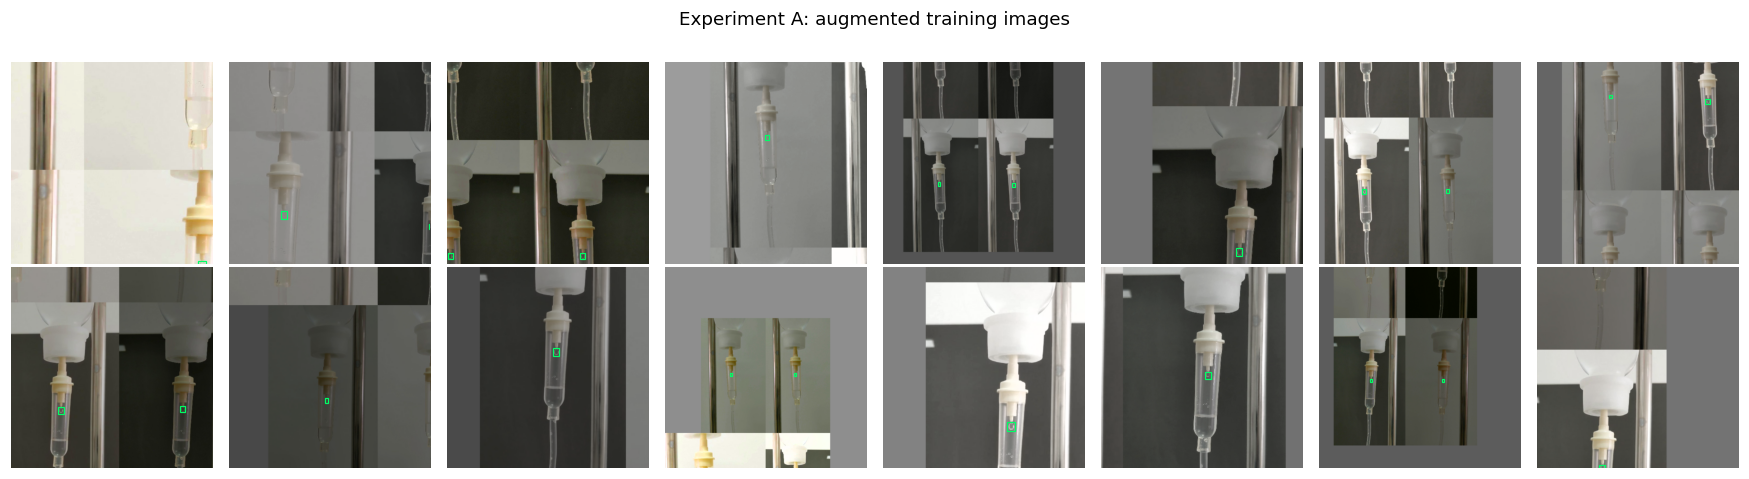

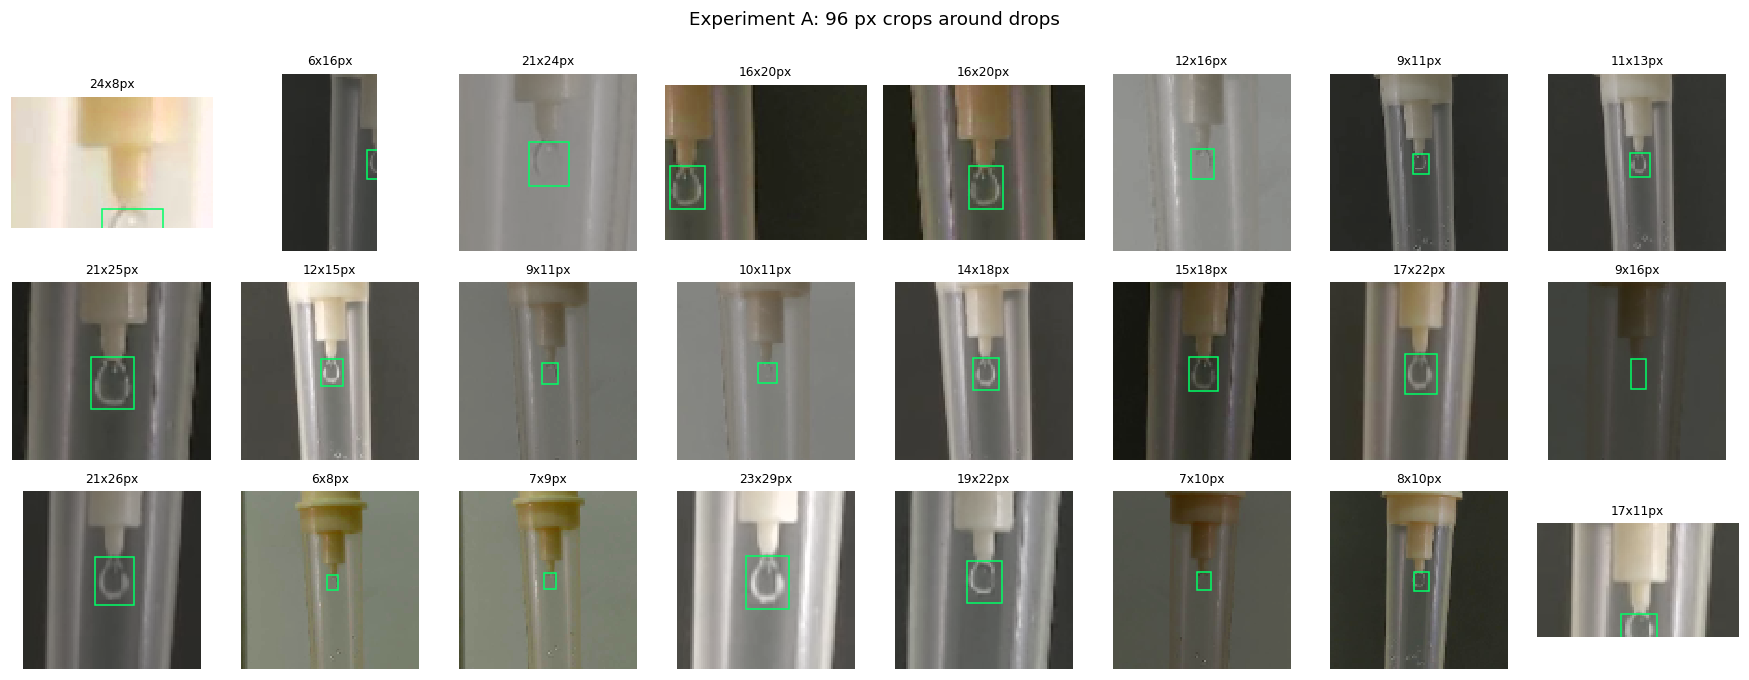

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1697.5±901.9 MB/s, size: 54.4 KB)
train: Scanning /content/dataset/labels/train.cache... 6442 images, 51 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6442/6442 1.2Git/s 0.0s
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


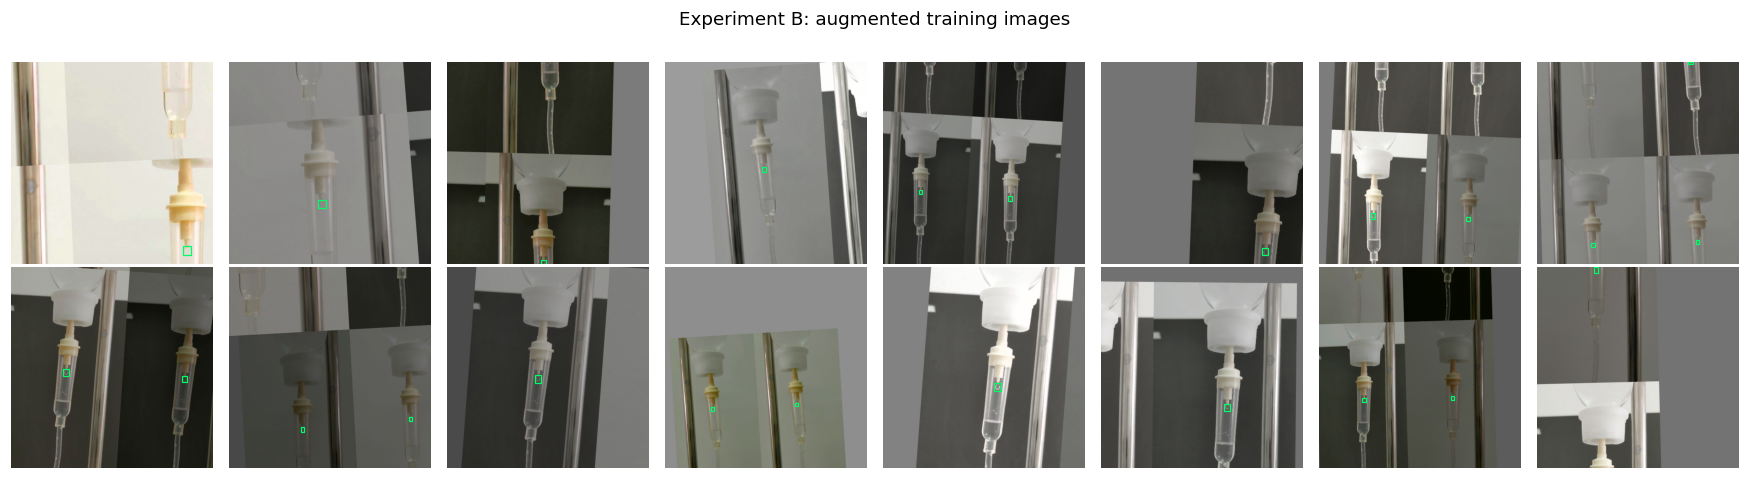

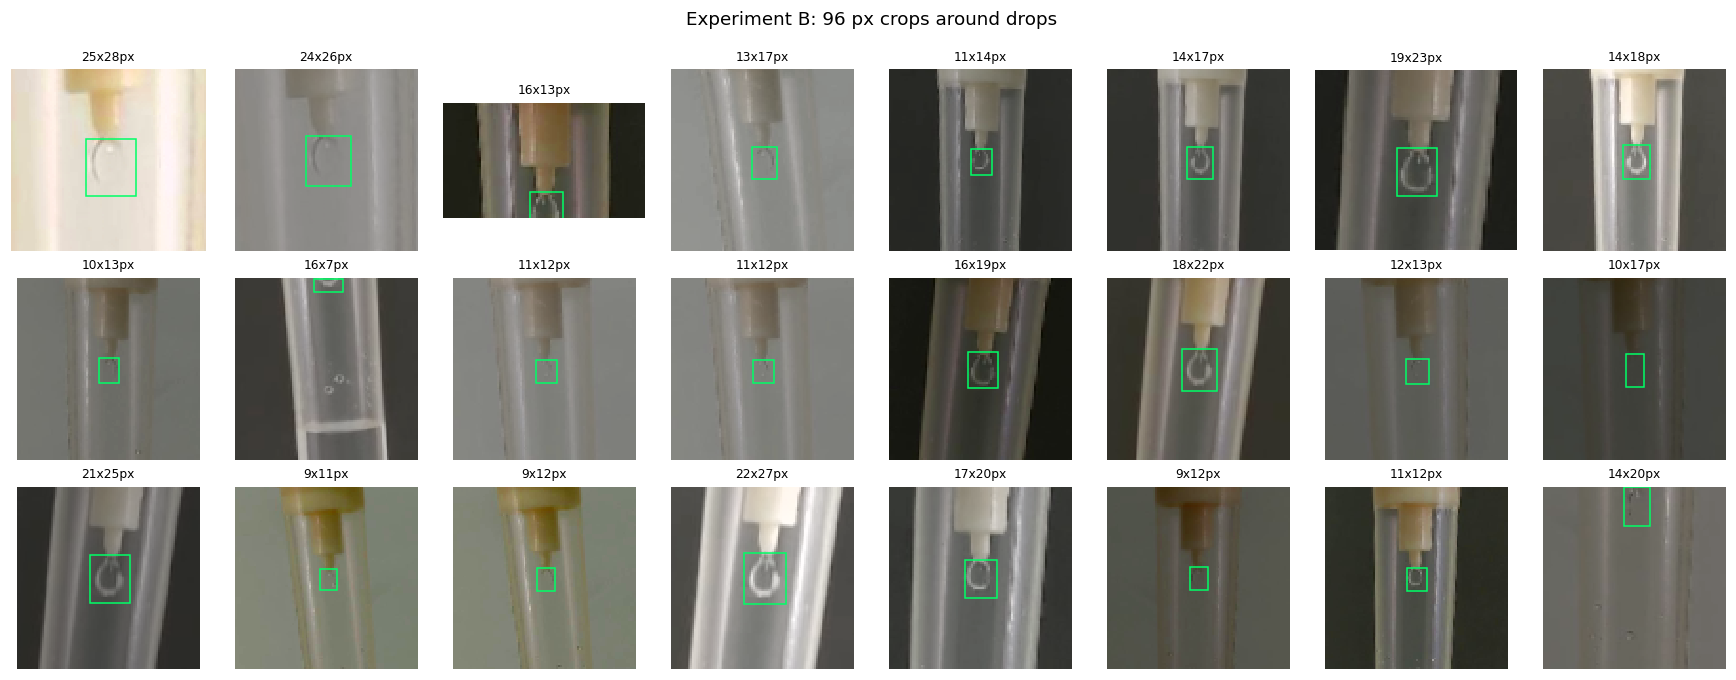

,experiment,boxes,images without a box,median w x h (px),tiny (<=120 px^2),min side < 6 px
0,no augmentation,1501,-,13.0 x 16.3,9%,2%
1,A,508,34,10.3 x 12.9,45%,8%
2,B,452,16,12.6 x 15.7,21%,6%


In [7]:
from ultralytics.cfg import get_cfg
from ultralytics.data import build_yolo_dataset
from ultralytics.data.utils import check_det_dataset


def augmented_samples(aug, n, seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    cfg = get_cfg(overrides={"data": str(DATA_YAML), "imgsz": IMGSZ, **aug})
    data = check_det_dataset(str(DATA_YAML))
    ds = build_yolo_dataset(cfg, data["train"], batch=BATCH, data=data, mode="train", stride=32)
    idx = random.Random(seed).sample(range(len(ds)), min(n, len(ds)))
    out = []
    for i in idx:
        s = ds[i]
        img = s["img"].permute(1, 2, 0).numpy()            # (H, W, 3) RGB uint8
        b = s["bboxes"].numpy().reshape(-1, 4)             # normalized xywh
        h, w = img.shape[:2]
        out.append((img, b * np.array([w, h, w, h])))
    return out


def preview(name, aug, n_show=16, n_stats=300):
    samples = augmented_samples(aug, n_stats)
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
    for ax, (img, b) in zip(axes.flat, samples[:n_show]):
        ax.imshow(img); ax.axis("off")
        for x, y, w, h in b:
            ax.add_patch(mpatches.Rectangle((x - w / 2, y - h / 2), w, h, fill=False, ec="#00ff66", lw=0.8))
    fig.suptitle(f"Experiment {name}: augmented training images", y=0.99); plt.tight_layout(); plt.show()

    crops = [(img, x, y, w, h) for img, b in samples for x, y, w, h in b][:24]
    fig, axes = plt.subplots(3, 8, figsize=(16, 6.2))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (img, x, y, w, h) in zip(axes.flat, crops):
        r = 48
        x0, y0 = int(max(0, x - r)), int(max(0, y - r))
        ax.imshow(img[y0:y0 + 2 * r, x0:x0 + 2 * r], interpolation="nearest")
        ax.add_patch(mpatches.Rectangle((x - w / 2 - x0, y - h / 2 - y0), w, h, fill=False, ec="#00ff66", lw=1))
        ax.set_title(f"{w:.0f}x{h:.0f}px", fontsize=8)
    fig.suptitle(f"Experiment {name}: 96 px crops around drops", y=0.99); plt.tight_layout(); plt.show()

    allb = np.concatenate([b for _, b in samples]) if samples else np.zeros((0, 4))
    return {"experiment": name, "boxes": len(allb), "images without a box": sum(len(b) == 0 for _, b in samples),
            "median w x h (px)": f"{np.median(allb[:, 2]):.1f} x {np.median(allb[:, 3]):.1f}",
            "tiny (<=120 px^2)": f"{(allb[:, 2] * allb[:, 3] <= TINY_AREA).mean():.0%}",
            "min side < 6 px": f"{(allb[:, 2:].min(1) < 6).mean():.0%}"}


aug_rows = [{"experiment": "no augmentation", "boxes": len(wh), "images without a box": "-",
             "median w x h (px)": f"{np.median(wh[:, 0]):.1f} x {np.median(wh[:, 1]):.1f}",
             "tiny (<=120 px^2)": f"{(wh[:, 0] * wh[:, 1] <= TINY_AREA).mean():.0%}",
             "min side < 6 px": f"{(np.minimum(wh[:, 0], wh[:, 1]) < 6).mean():.0%}"}]
for name, aug in EXPERIMENTS.items():
    aug_rows.append(preview(name, aug))
display(pd.DataFrame(aug_rows))

## 7. Training (resumable)
Each run writes to `MyDrive/iv_drip/runs/<name>/`. A `DONE` file marks a finished run, so re-running the notebook skips it.
If a run was interrupted, it resumes from `last.pt`.

In [8]:
def run_dir(name):
    return RUNS_DIR / RUN_NAMES[name]


def train_experiment(name):
    d = run_dir(name)
    last, best, done = d / "weights" / "last.pt", d / "weights" / "best.pt", d / "DONE"
    if done.exists() and best.exists():
        print(f"[{name}] already finished: {best}")
        return d
    t0 = time.time()
    if last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)
        resumable = ck.get("epoch", -1) >= 0 and ck.get("optimizer") is not None
        del ck
        if not resumable:
            # Finished run whose DONE marker is missing. Don't call resume here: Ultralytics 8.4 would
            # silently start a NEW 100-epoch training on its demo dataset instead.
            print(f"[{name}] run already finished (no DONE marker); marking it done")
        else:
            print(f"[{name}] resuming from {last}")
            YOLO(str(last)).train(resume=True)
    else:
        print(f"[{name}] training from {BASE_WEIGHTS} with {EXPERIMENTS[name]}")
        model = YOLO(BASE_WEIGHTS)
        model.train(**COMMON, **EXPERIMENTS[name], name=RUN_NAMES[name])
    assert best.exists(), f"best.pt missing in {d}"
    done.write_text(datetime.now().isoformat())
    print(f"[{name}] finished in {(time.time() - t0) / 60:.1f} min -> {best}")
    return d

In [9]:
train_experiment("A")

[A] resuming from /content/drive/MyDrive/iv_drip/runs/expA_v8n_640/weights/last.pt
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/iv_drip/runs/expA

PosixPath('/content/drive/MyDrive/iv_drip/runs/expA_v8n_640')

In [10]:
train_experiment("B")

[B] training from yolov8n.pt with {'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4, 'degrees': 5.0, 'translate': 0.3, 'scale': 0.3, 'shear': 0.0, 'perspective': 0.0, 'flipud': 0.0, 'fliplr': 0.5, 'mosaic': 1.0, 'mixup': 0.0, 'close_mosaic': 15}
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=64

PosixPath('/content/drive/MyDrive/iv_drip/runs/expB_v8n_640')

## 8. Training curves and Ultralytics' own plots
Val recall, precision and mAP50 per epoch for both runs. The dot marks the epoch that `best.pt` comes from (Ultralytics picks it by fitness = 0.1·mAP50 + 0.9·mAP50-95).

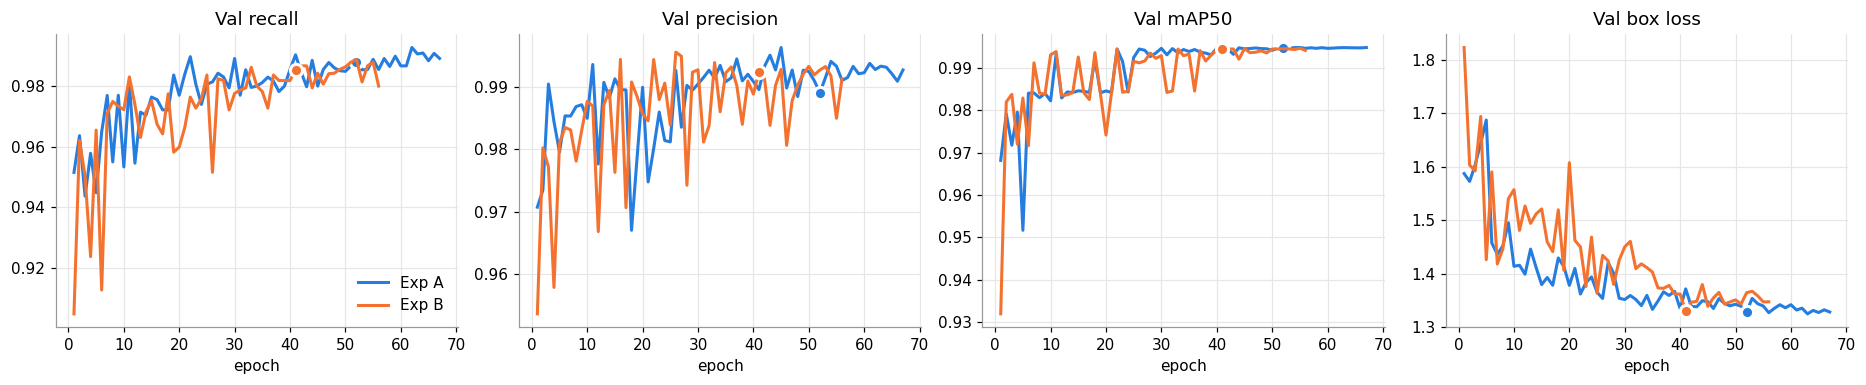

Experiment A: 67 epochs run (early stop if < 80); best epoch 52
results.png


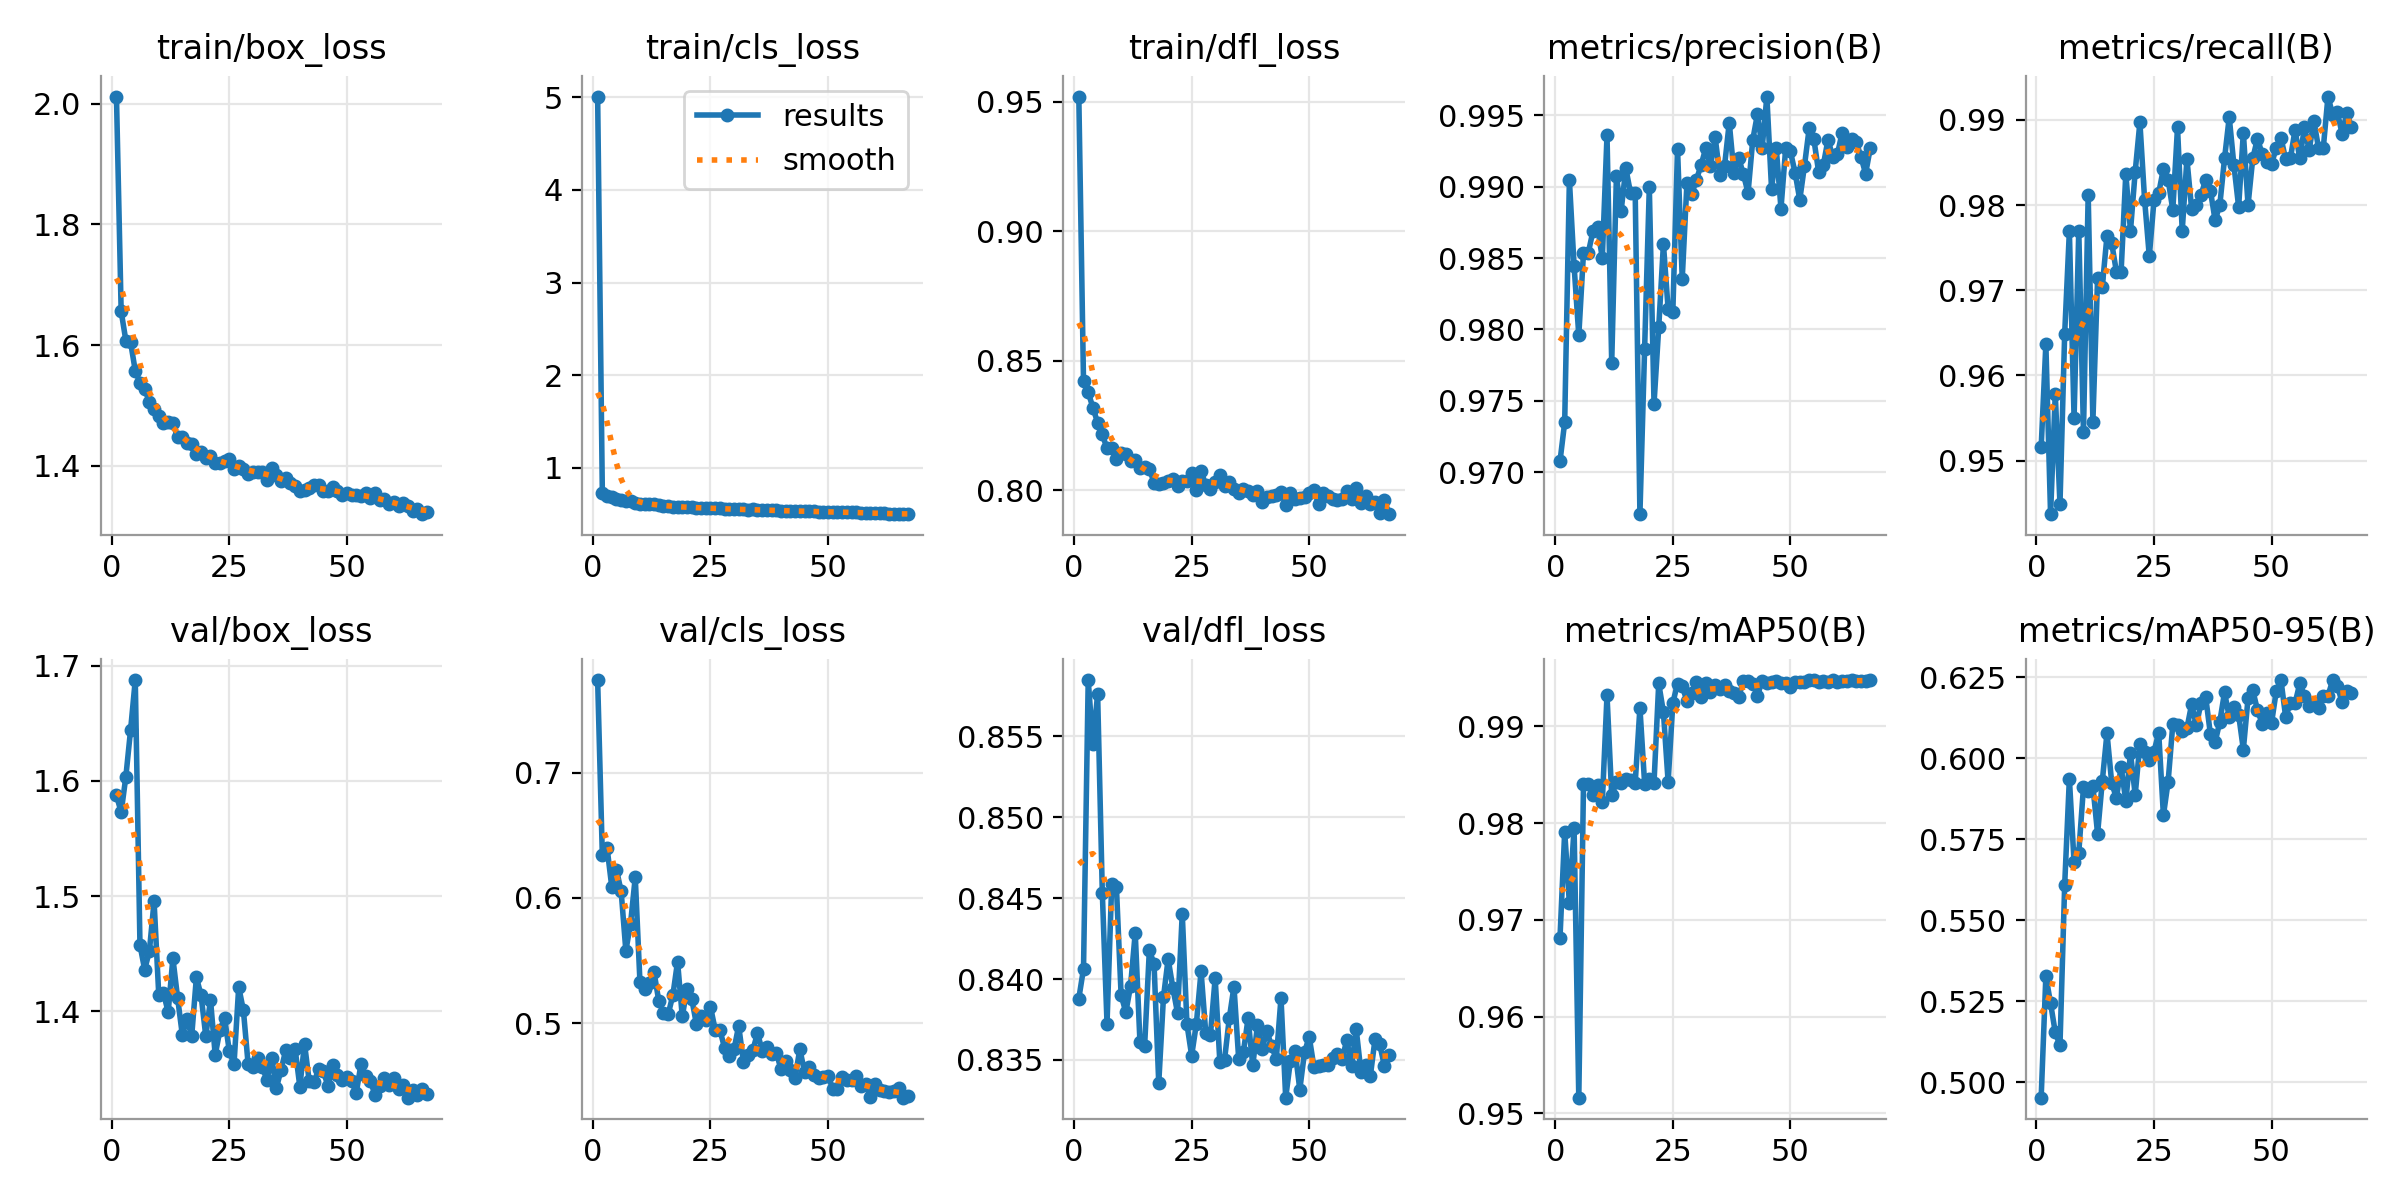

train_batch0.jpg


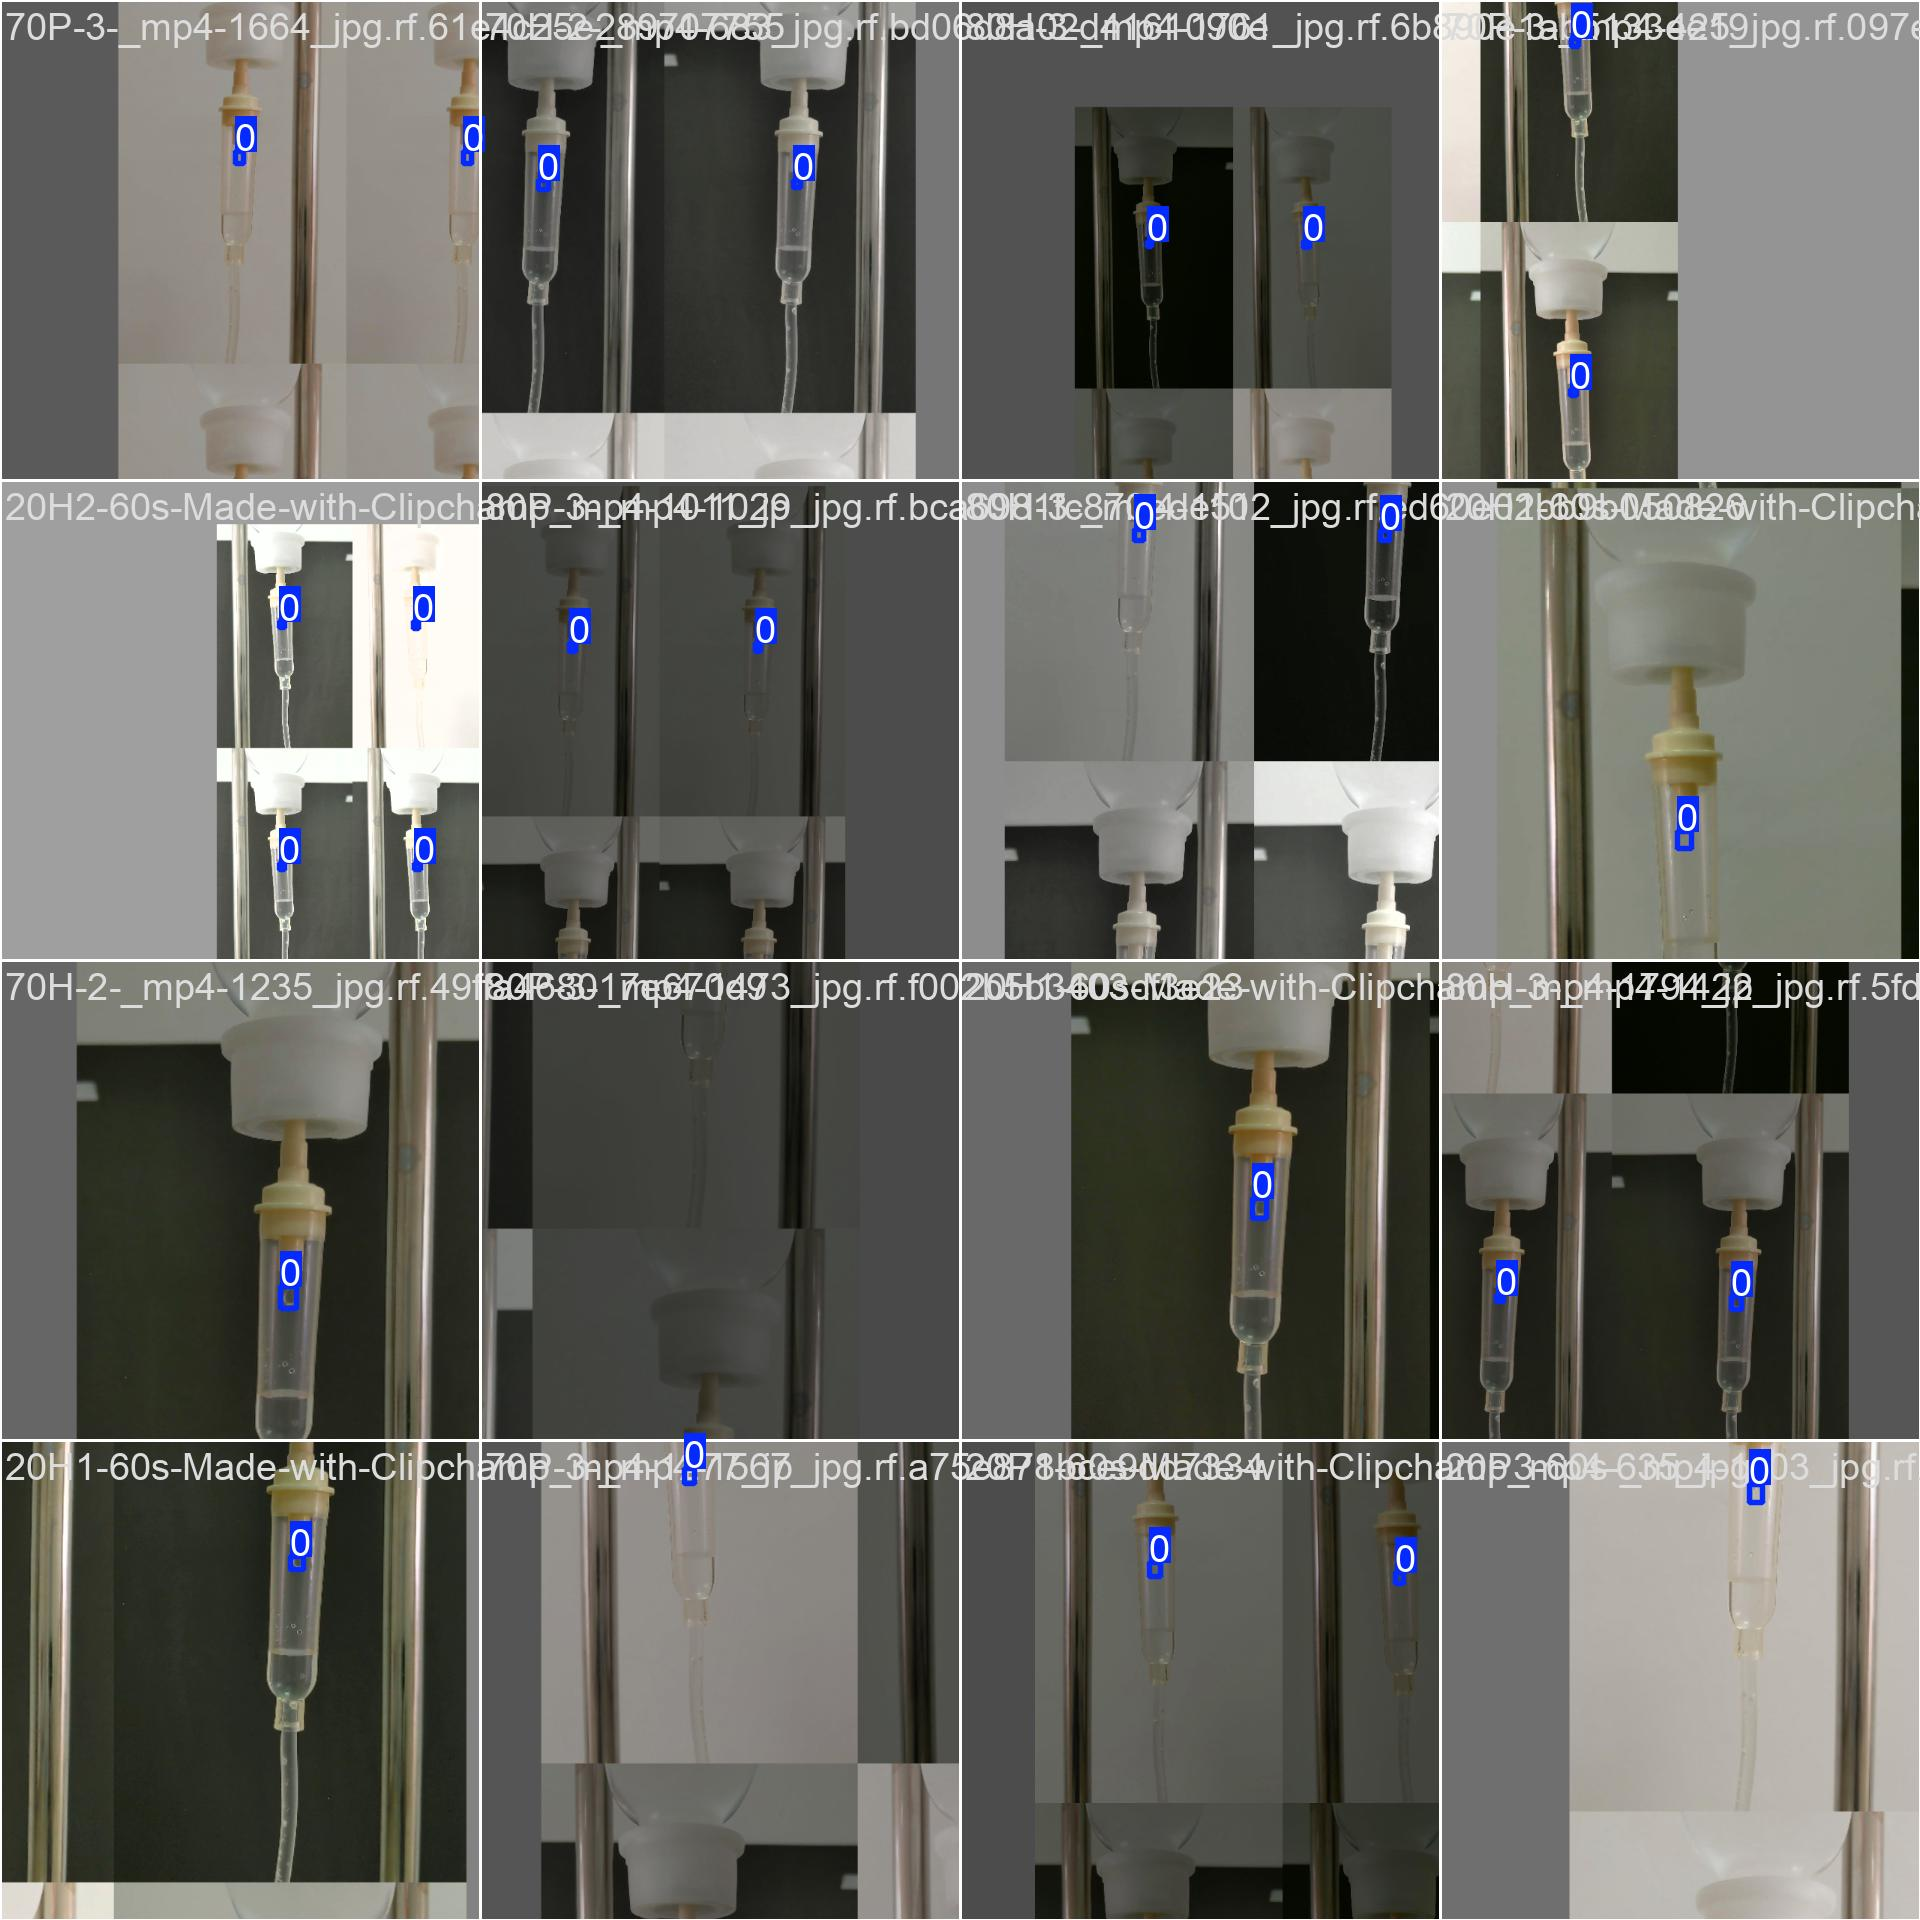

train_batch1.jpg


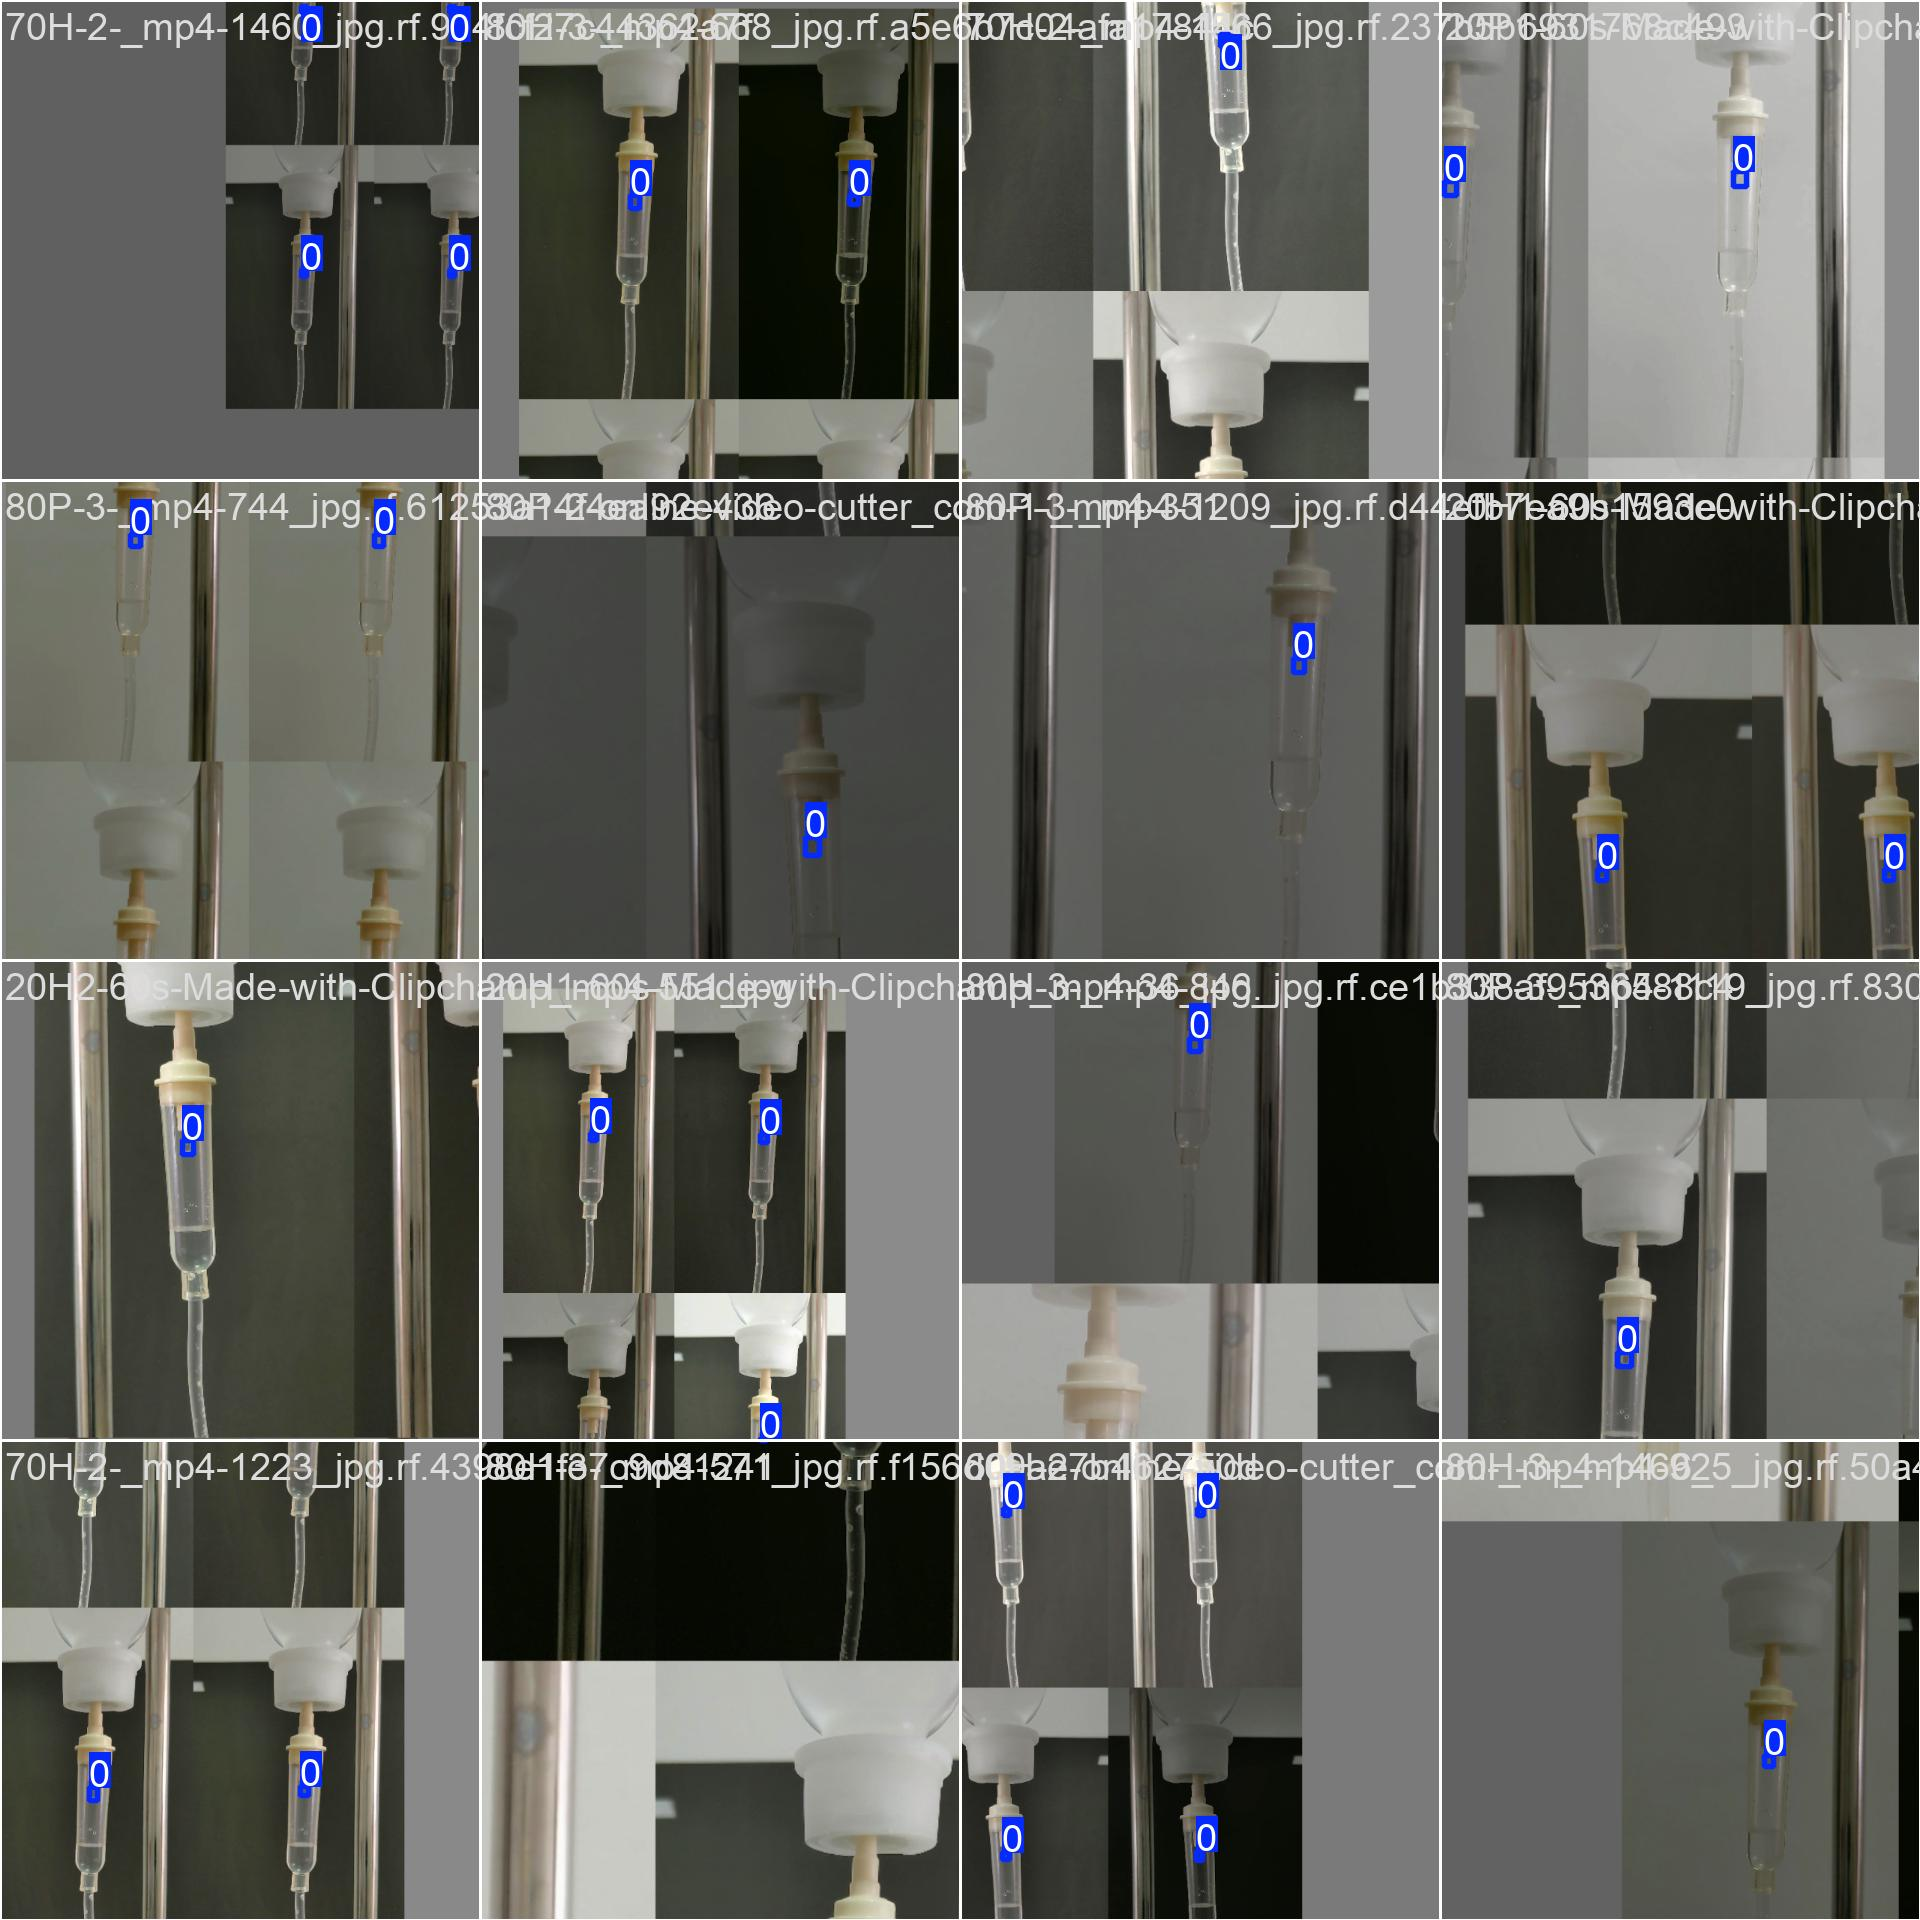

train_batch2.jpg


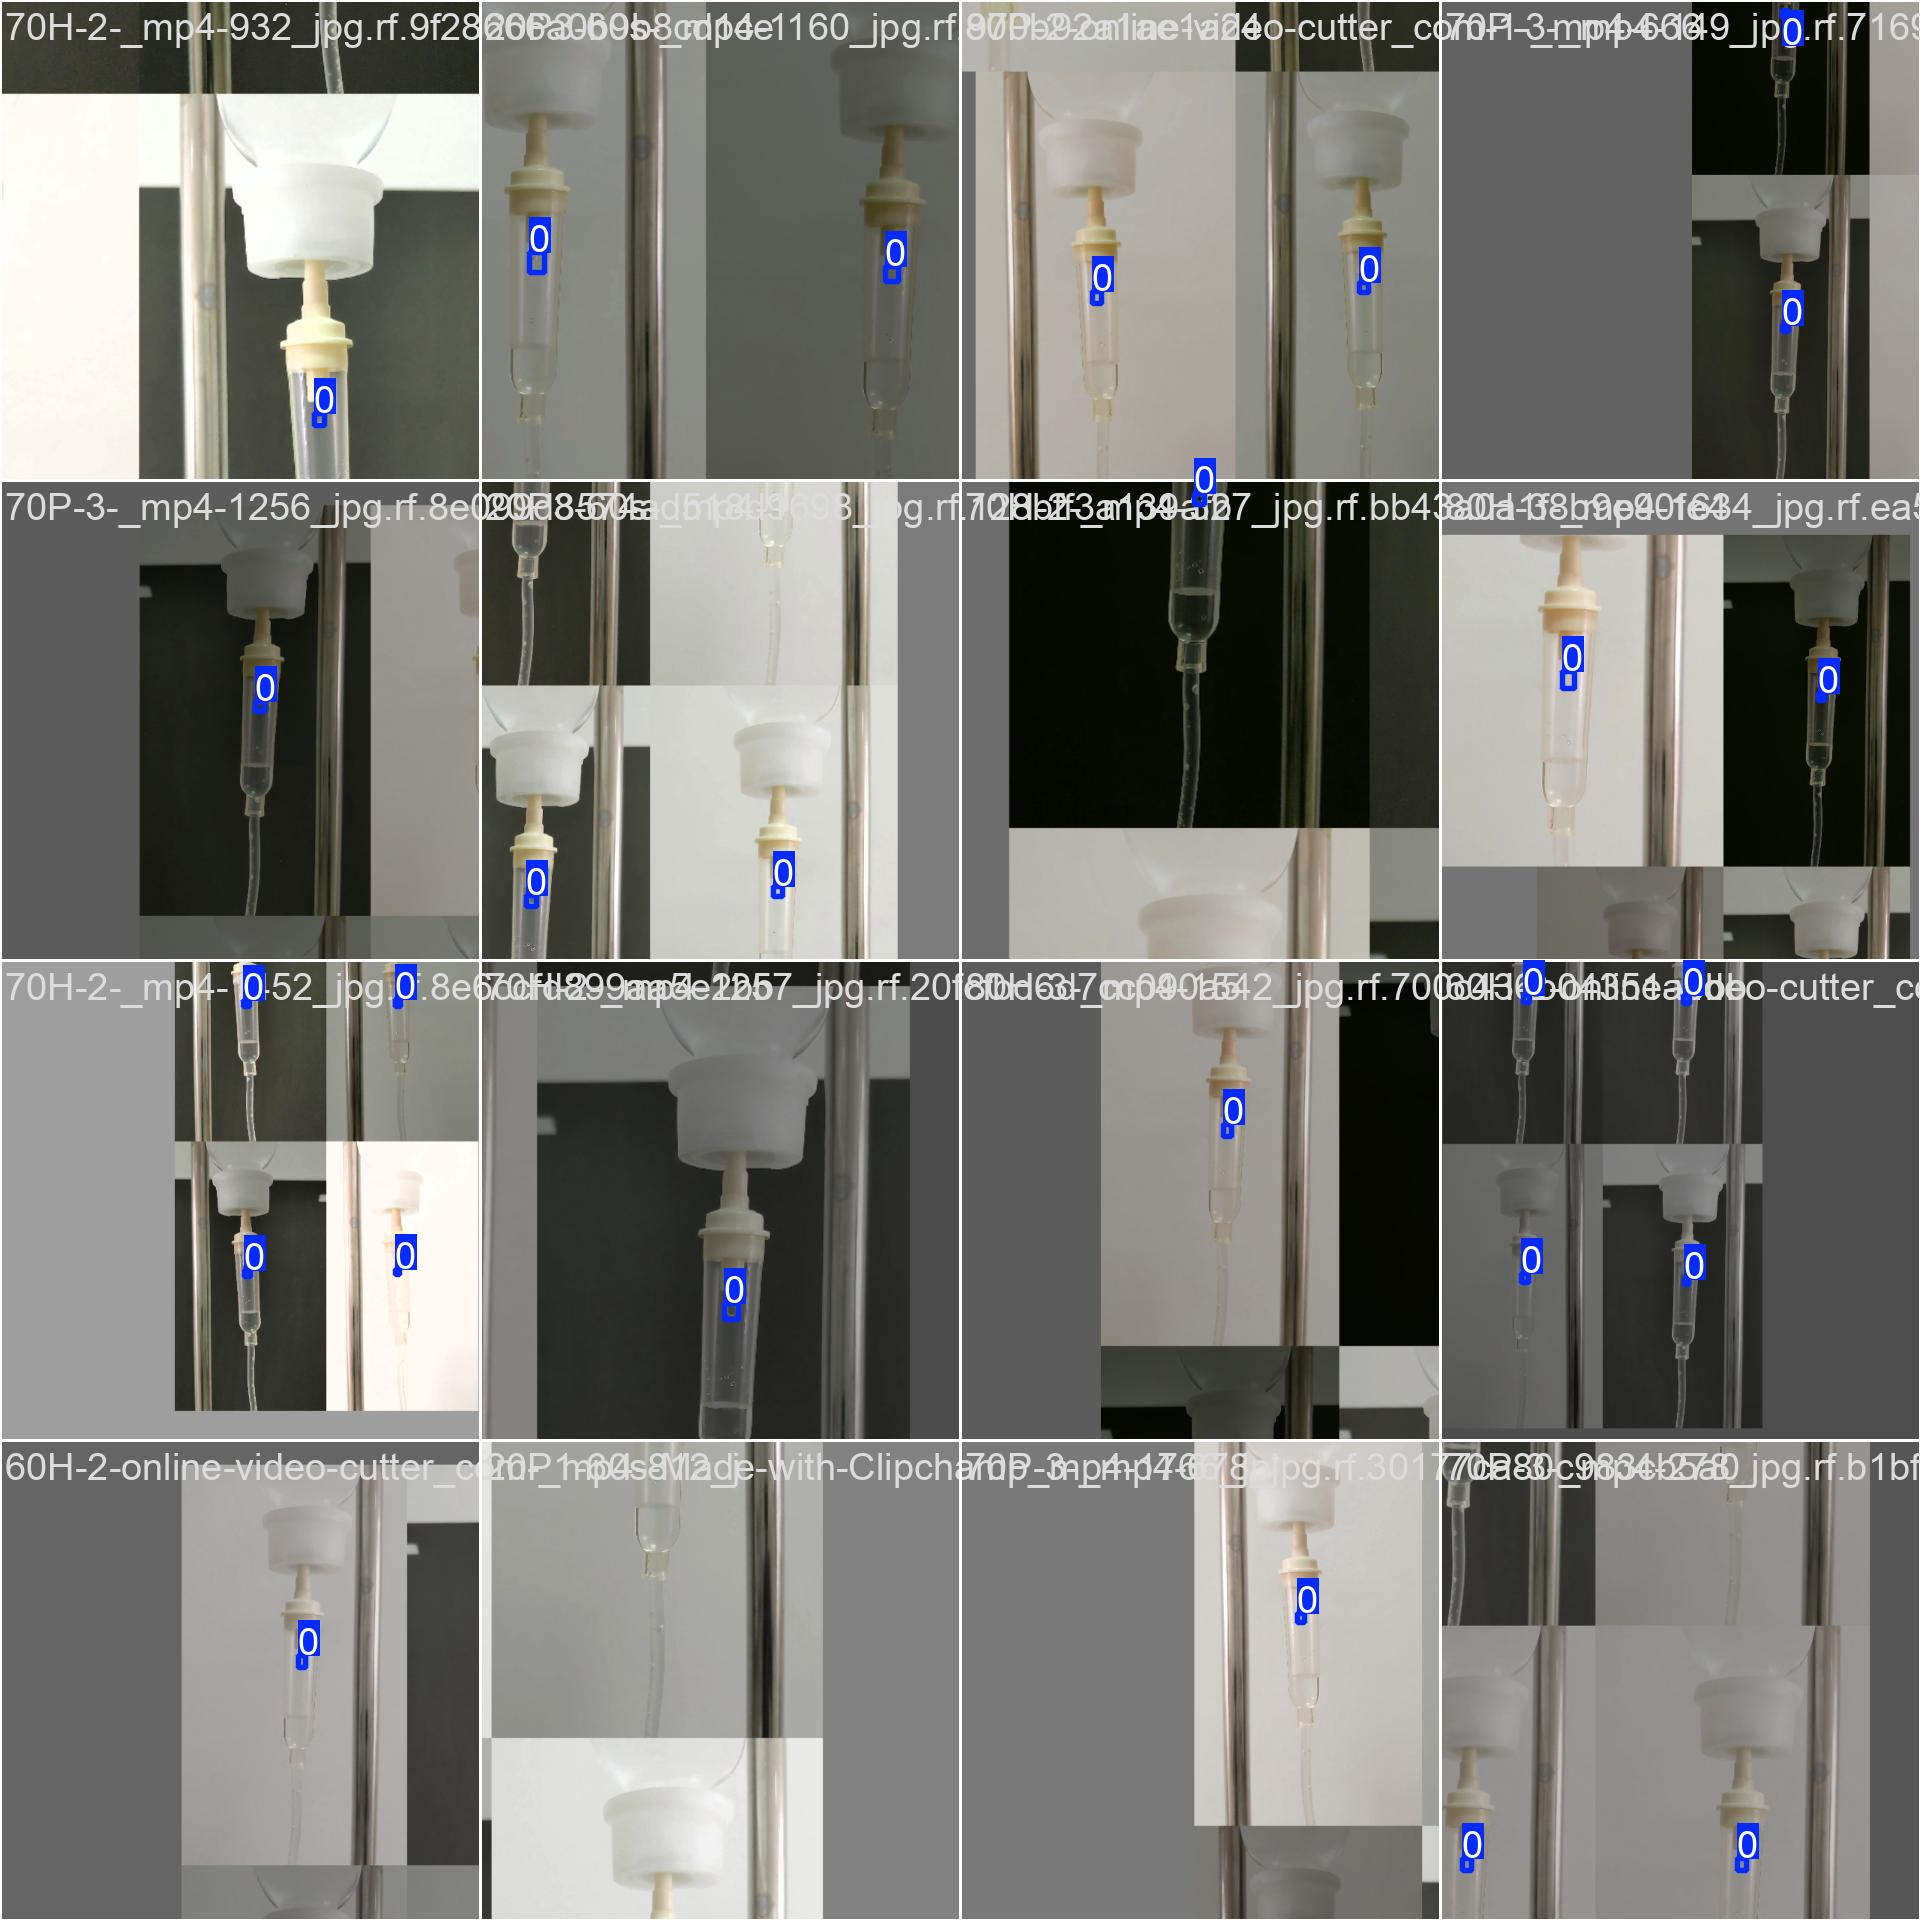

Experiment B: 56 epochs run (early stop if < 80); best epoch 41
results.png


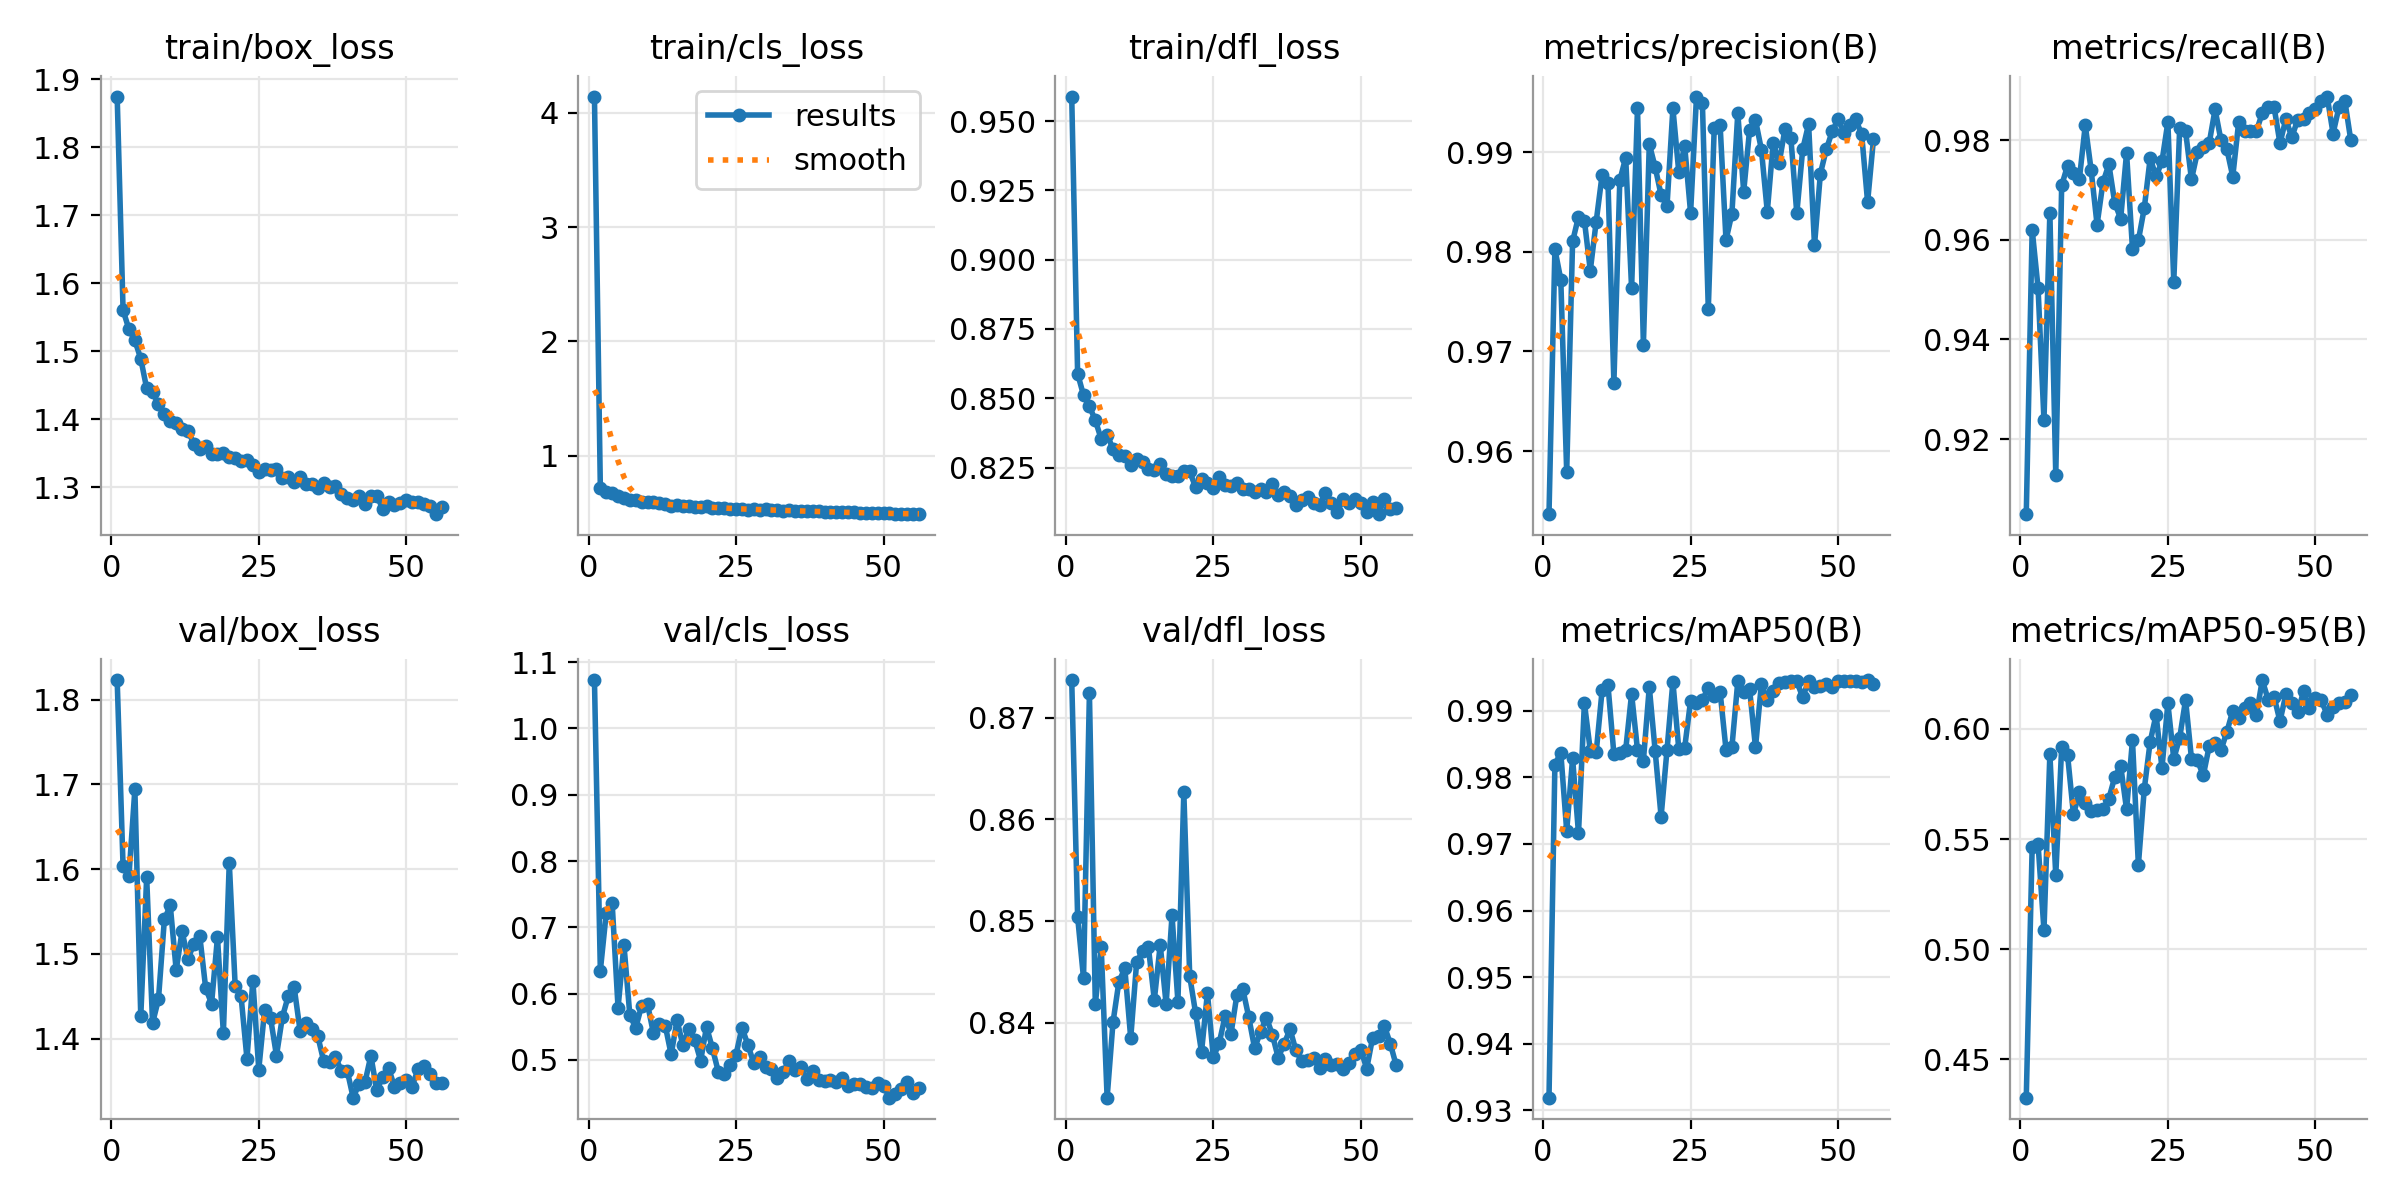

train_batch0.jpg


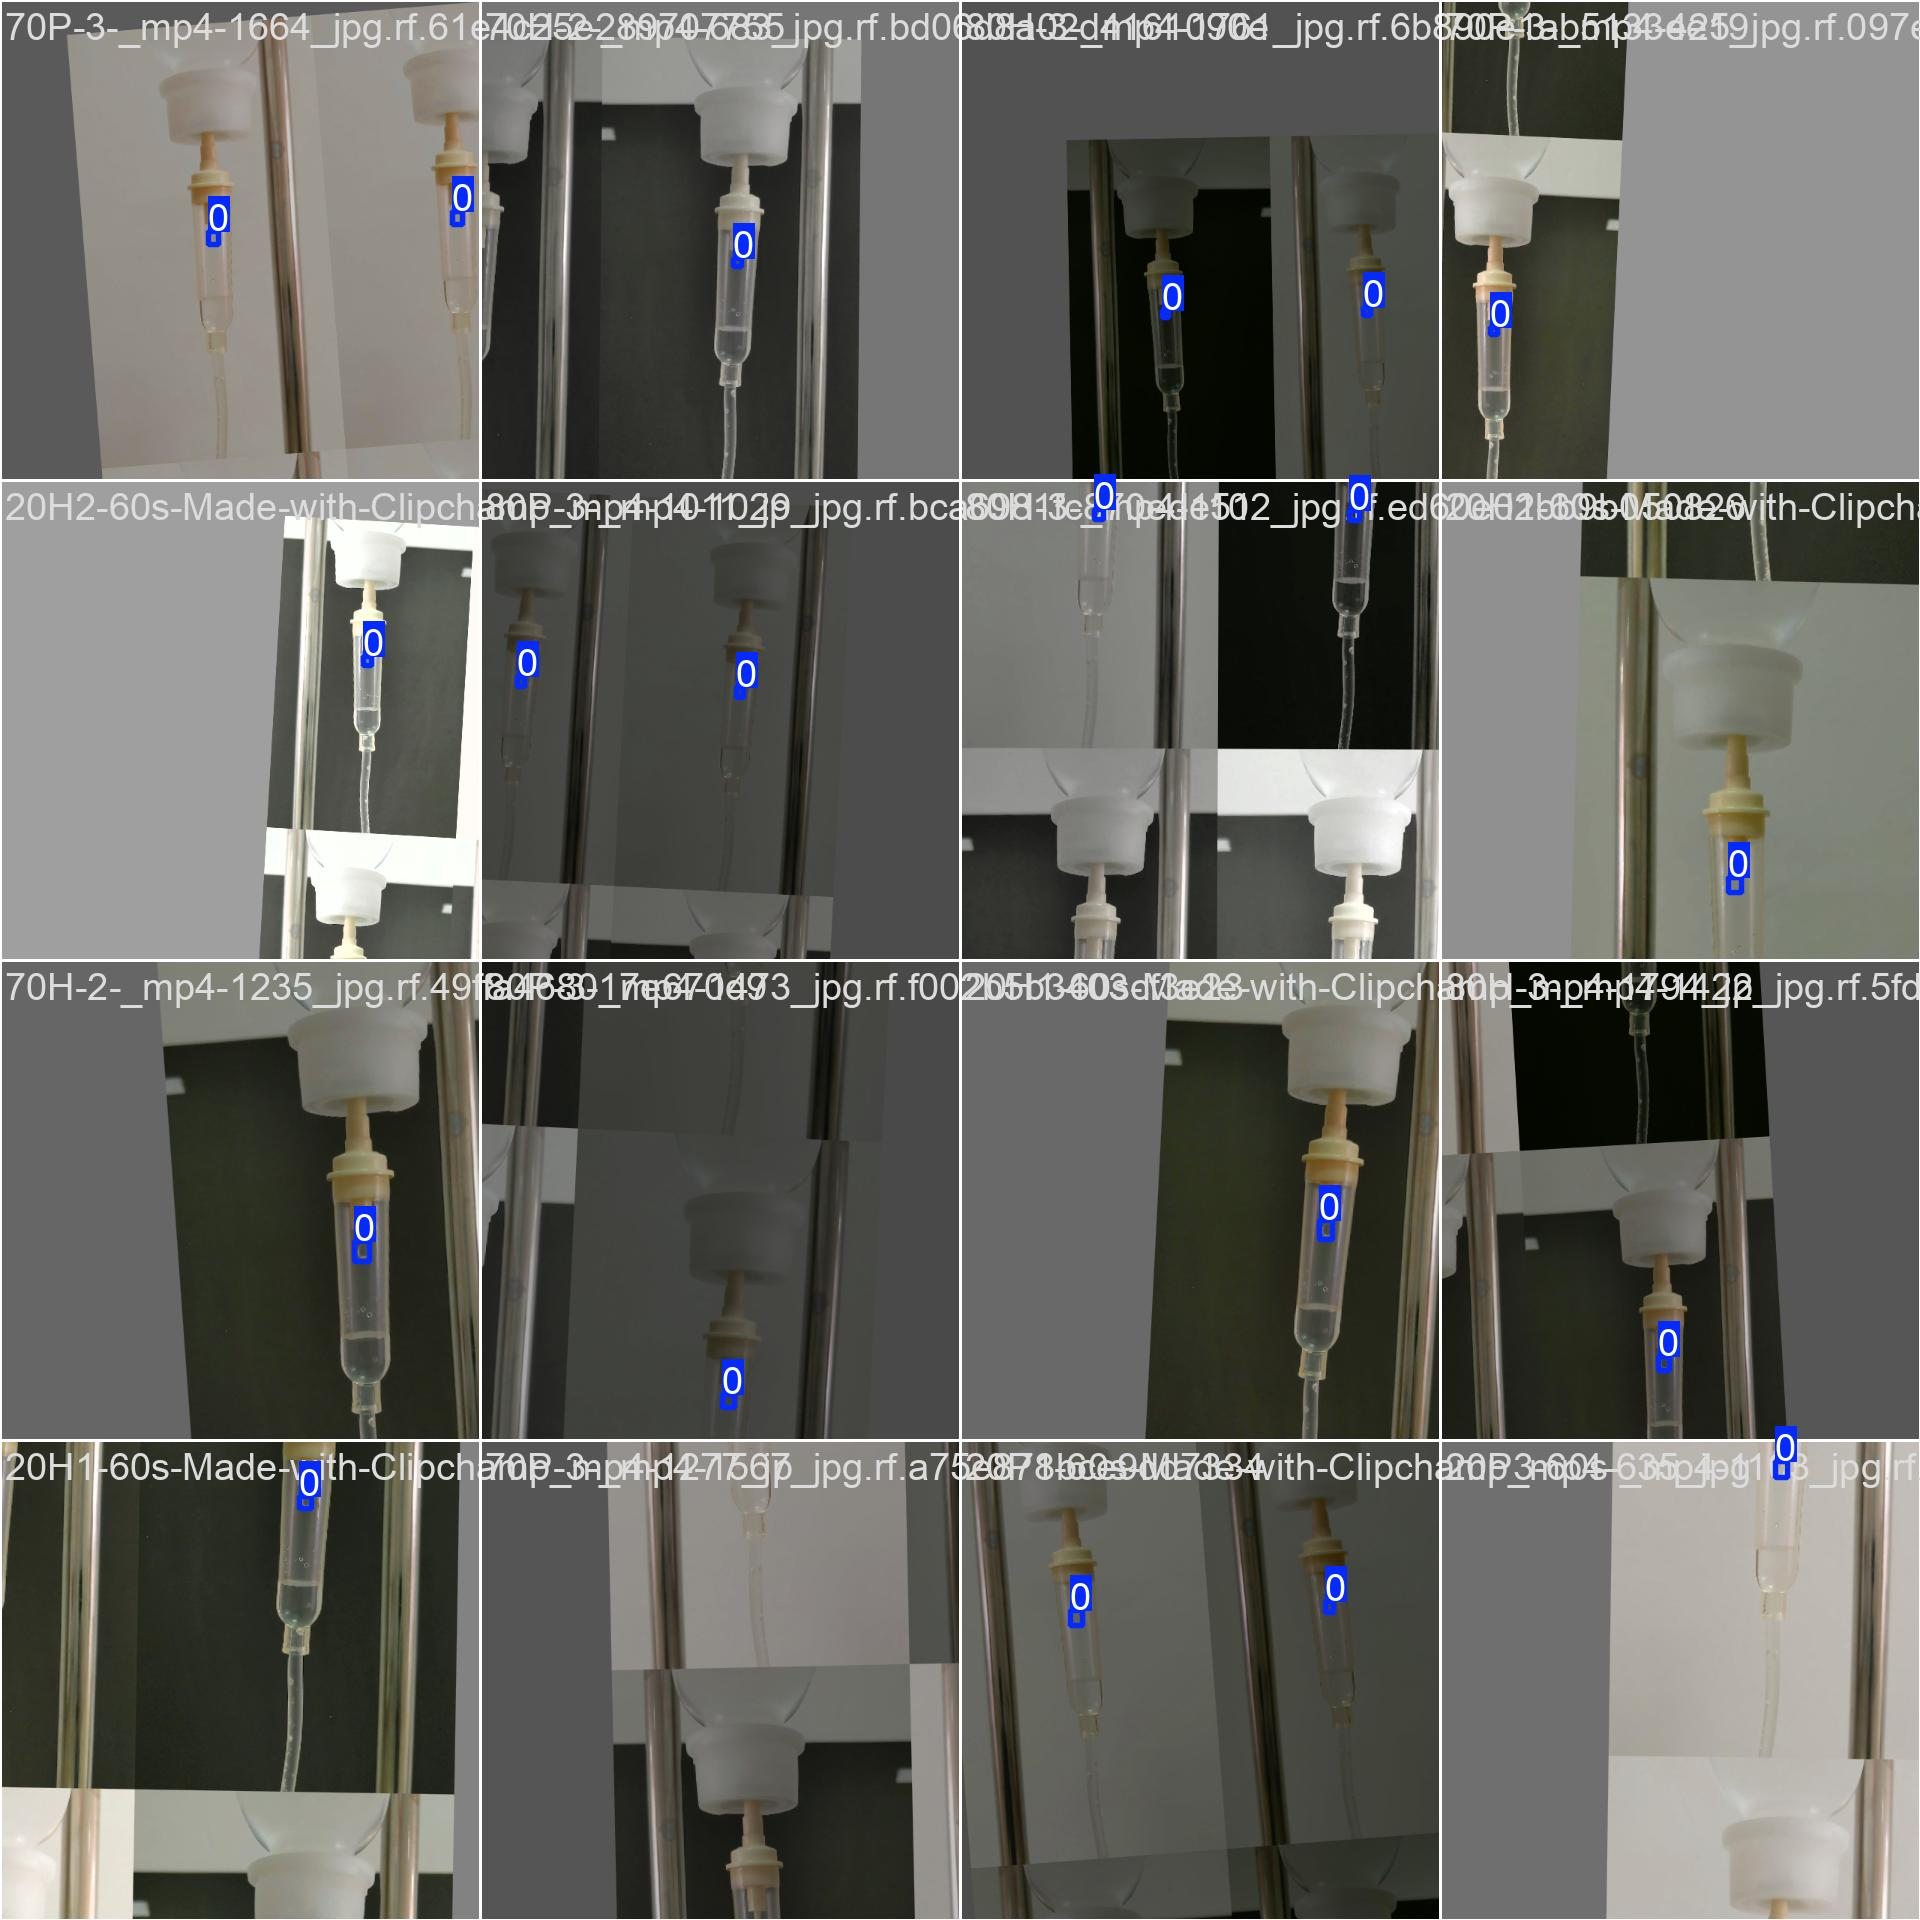

train_batch1.jpg


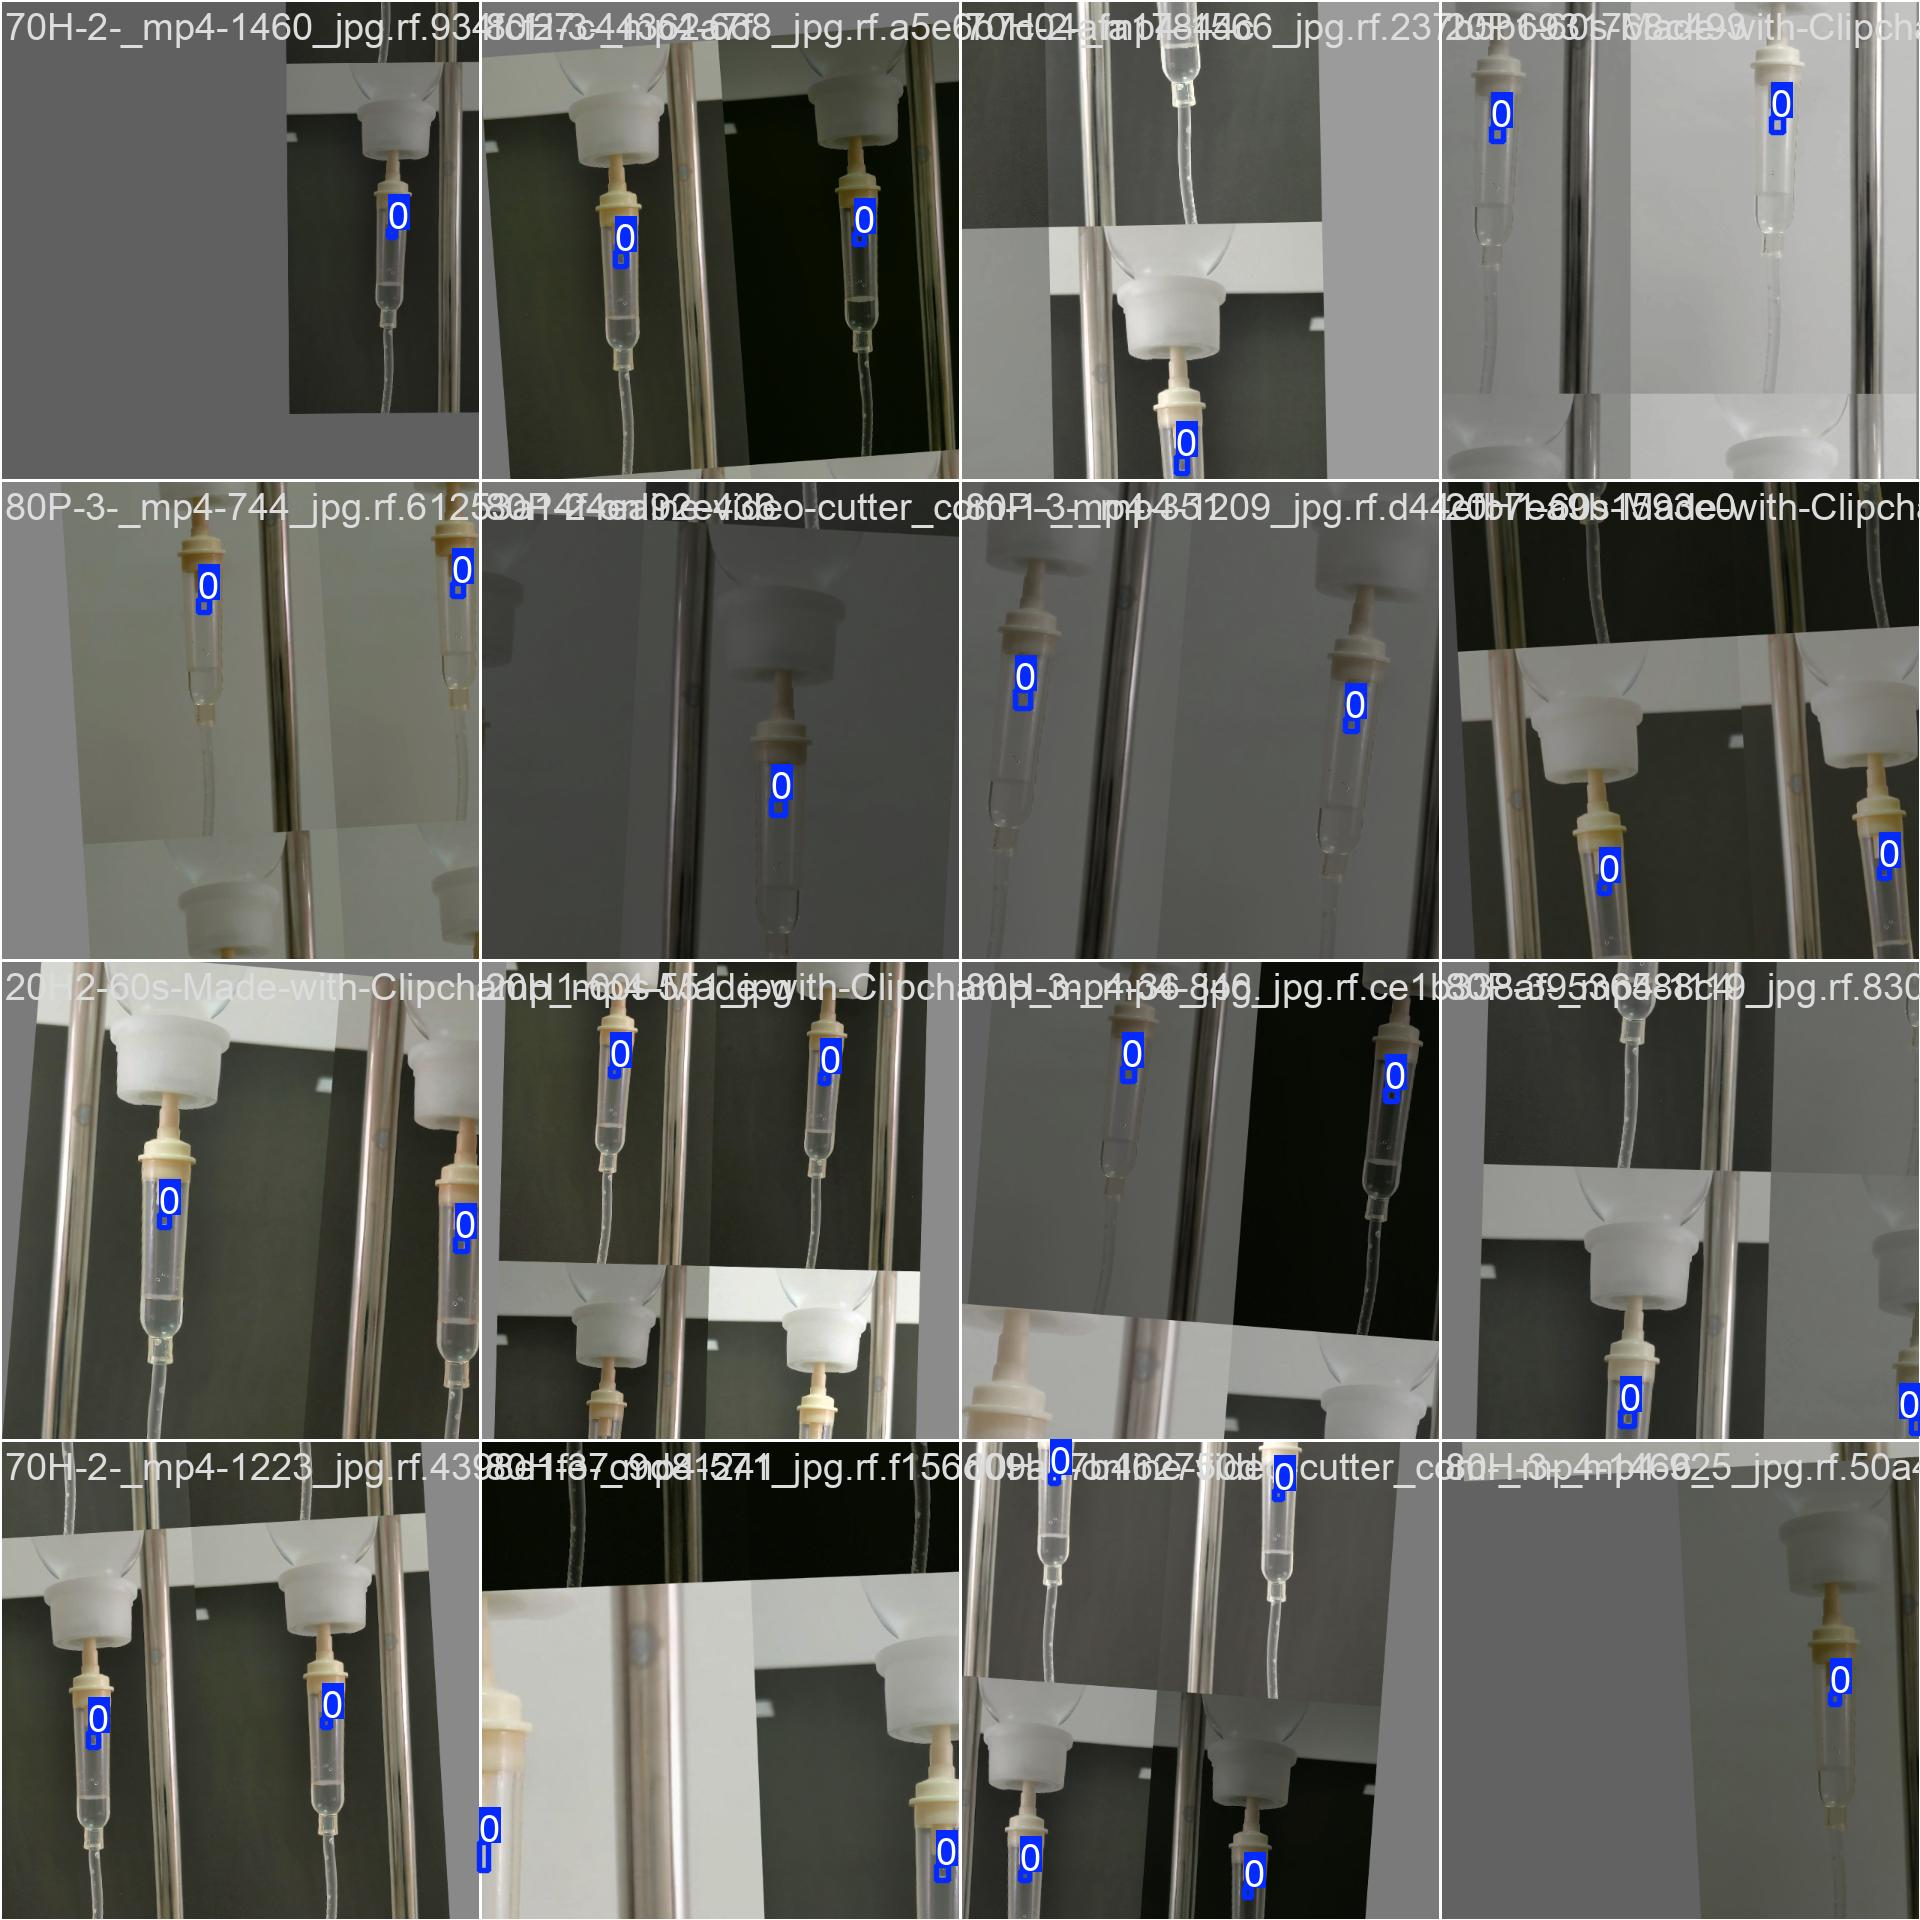

train_batch2.jpg


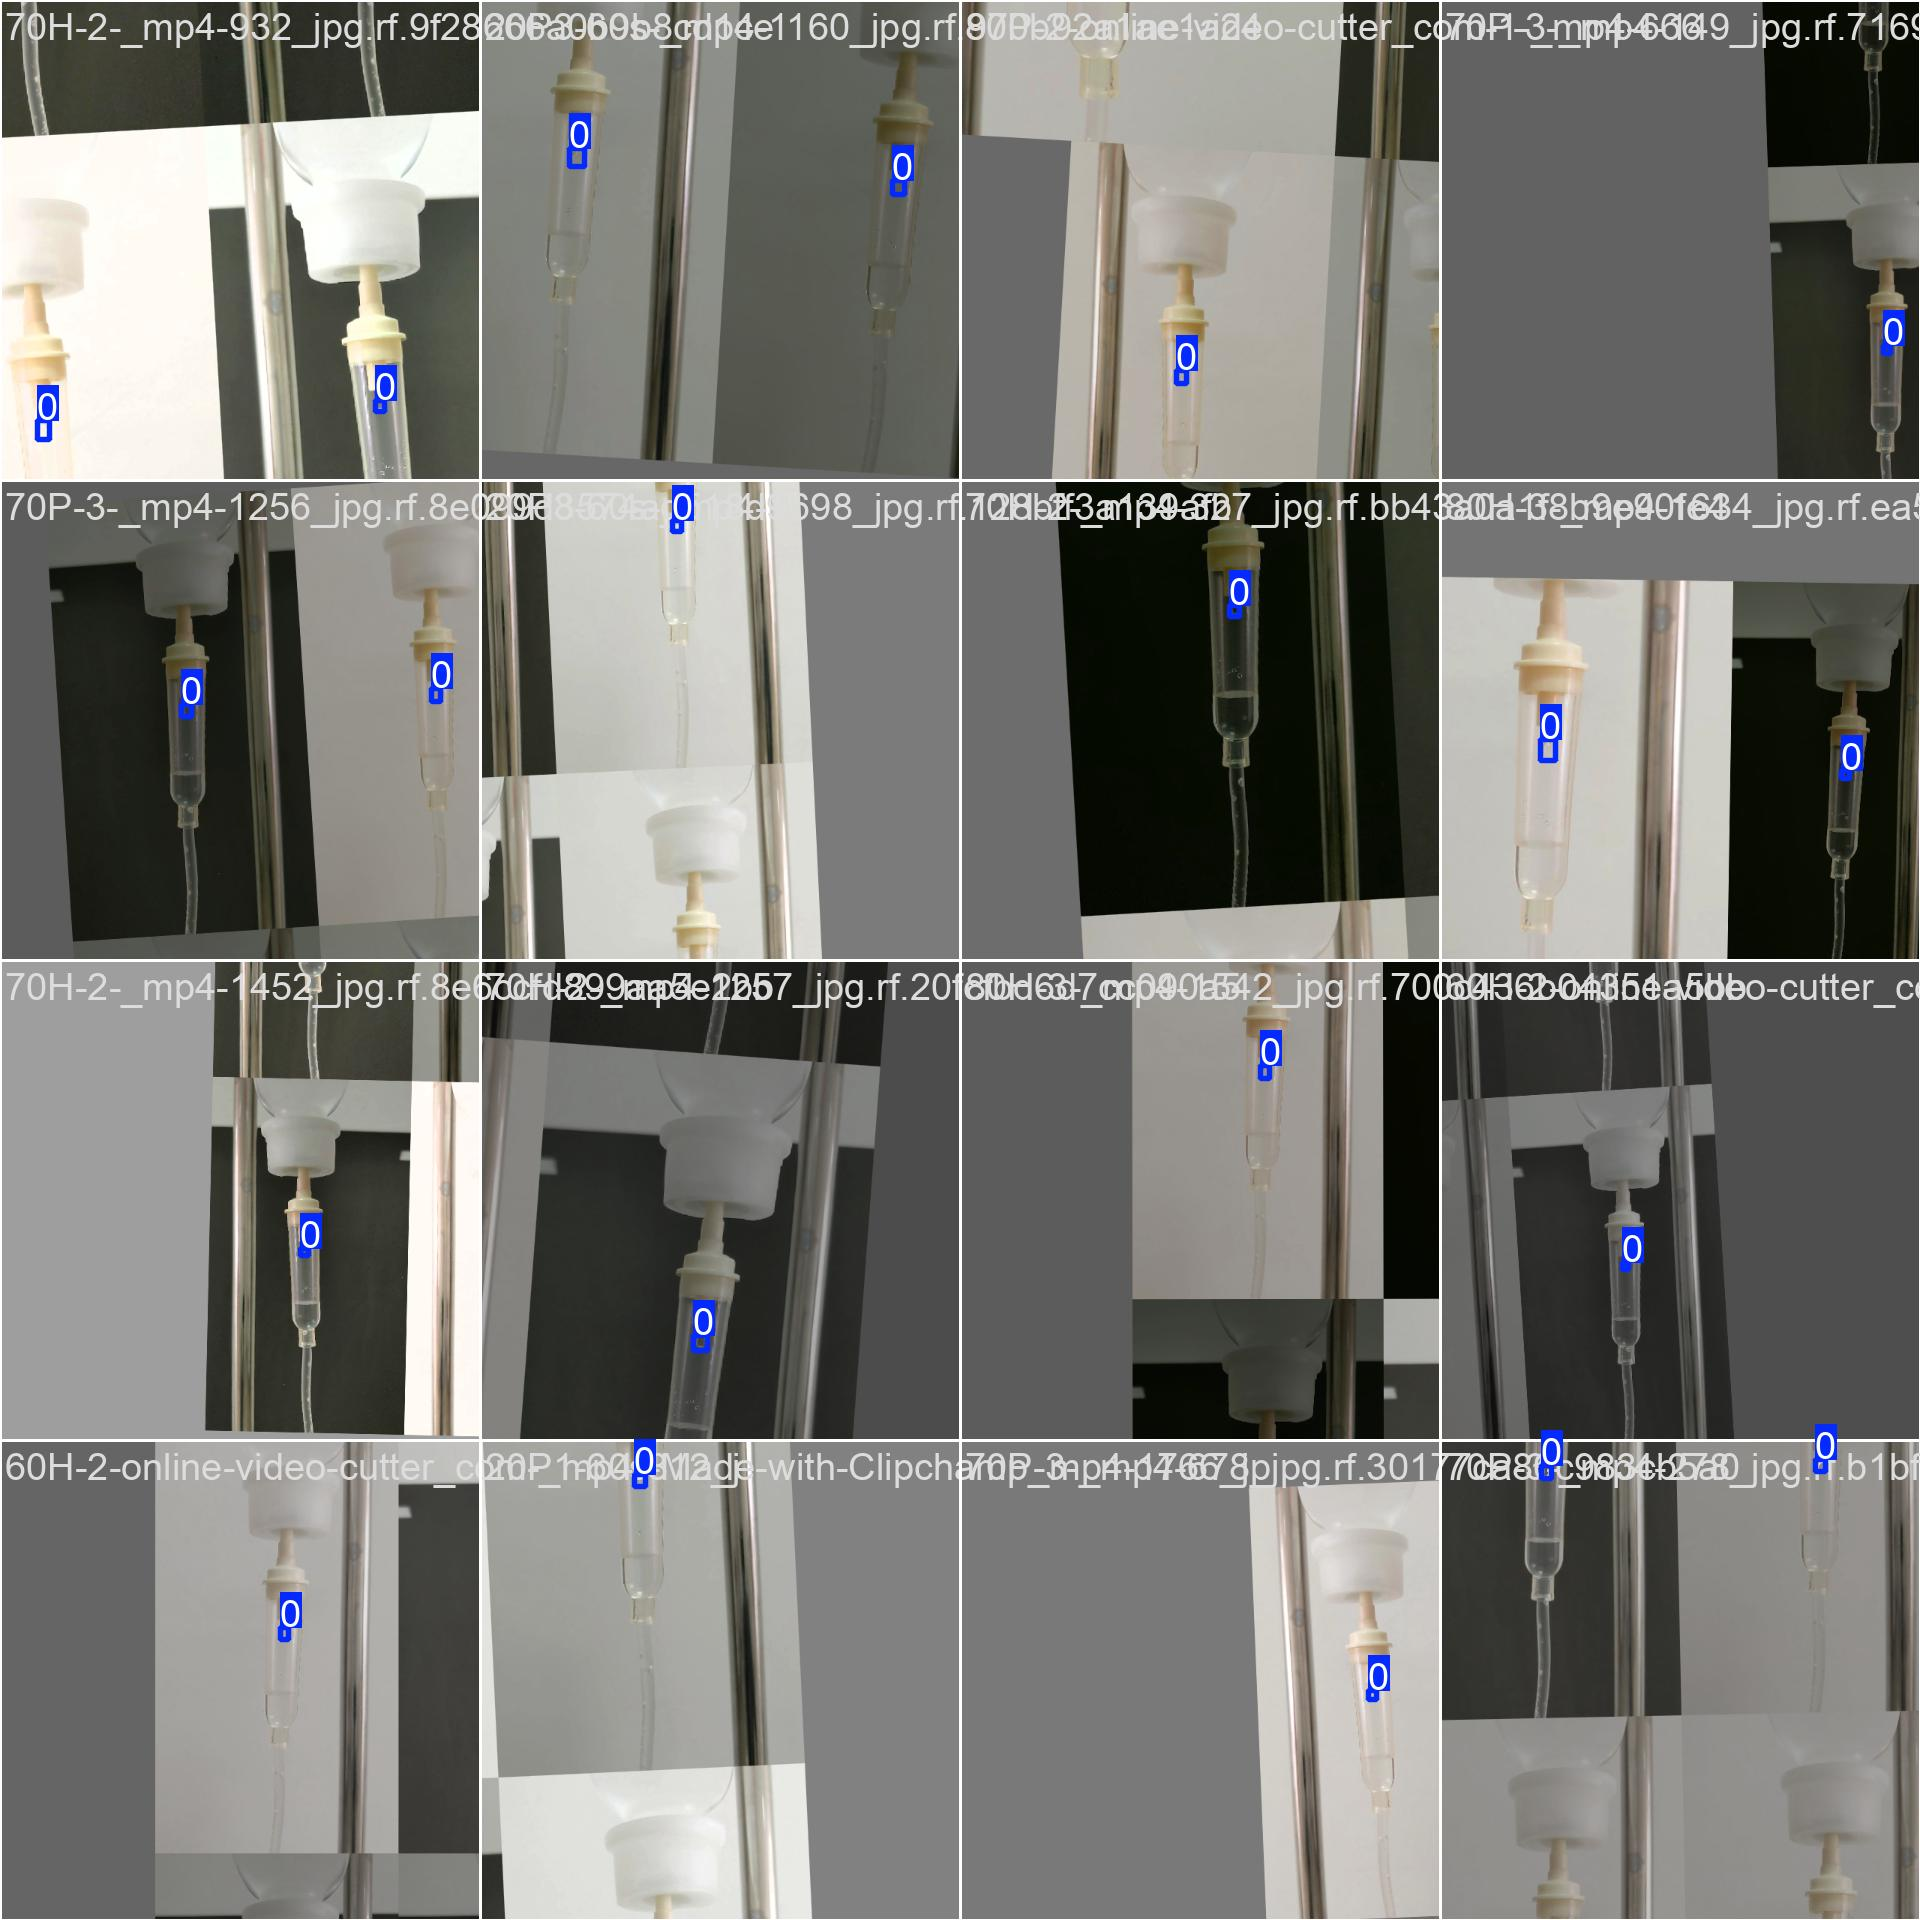

In [11]:
def load_results(name):
    df = pd.read_csv(run_dir(name) / "results.csv")
    df.columns = [c.strip() for c in df.columns]
    df["fitness"] = 0.1 * df["metrics/mAP50(B)"] + 0.9 * df["metrics/mAP50-95(B)"]
    return df


RESULTS = {k: load_results(k) for k in EXPERIMENTS}
panels = [("metrics/recall(B)", "Val recall"), ("metrics/precision(B)", "Val precision"),
          ("metrics/mAP50(B)", "Val mAP50"), ("val/box_loss", "Val box loss")]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (col, title) in zip(axes, panels):
    for k, df in RESULTS.items():
        ax.plot(df["epoch"], df[col], color=COLORS[k], lw=2, label=f"Exp {k}")
        b = df["fitness"].idxmax()
        ax.plot(df.loc[b, "epoch"], df.loc[b, col], "o", ms=8, color=COLORS[k], mec="white", mew=2)
    ax.set_title(title); ax.set_xlabel("epoch")
axes[0].legend(frameon=False)
plt.tight_layout()
fig.savefig(OUT_DIR / "compare_training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

for k in EXPERIMENTS:
    d = run_dir(k)
    print(f"Experiment {k}: {len(RESULTS[k])} epochs run (early stop if < {EPOCHS}); "
          f"best epoch {int(RESULTS[k].loc[RESULTS[k]['fitness'].idxmax(), 'epoch'])}")
    for f in ["results.png"] + sorted(p.name for p in d.glob("train_batch*.jpg"))[:3]:
        if (d / f).exists():
            print(f); display(IPImage(filename=str(d / f), width=900))

## 9. Ultralytics validation of each `best.pt` on val
Standard mAP50, mAP50-95, precision and recall. Ultralytics reports P and R at the confidence that maximizes F1, so section 10 also measures recall at a fixed threshold.

In [12]:
VAL_METRICS = {}
for k in EXPERIMENTS:
    m = YOLO(str(run_dir(k) / "weights" / "best.pt"))
    r = m.val(data=str(DATA_YAML), split="val", imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=True,
              project=str(run_dir(k)), name="val_best", exist_ok=True, verbose=False)
    VAL_METRICS[k] = {"mAP50": r.box.map50, "mAP50-95": r.box.map, "precision": r.box.mp, "recall": r.box.mr}
display(pd.DataFrame(VAL_METRICS).T.round(4))

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2164.8±904.5 MB/s, size: 67.0 KB)
val: Scanning /content/dataset/labels/val.cache... 1681 images, 35 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1681/1681 503.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 53/53 3.1it/s 16.9s
                   all       1681       1651      0.988      0.987      0.994      0.624
Speed: 0.8ms preprocess, 2.4ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/drive/MyDrive/iv_drip/runs/expA_v8n_640/val_best
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 954.1±312.5 MB/s, size: 27.5 

,mAP50,mAP50-95,precision,recall
A,0.9941,0.6243,0.9879,0.9873
B,0.9944,0.6228,0.9922,0.9855


## 10. Recall where it matters for counting
One prediction pass per model at a very low confidence, then every threshold is evaluated from that pass:

* **recall and precision at a fixed confidence** (0.25), boxes matched greedily by IoU ≥ 0.5 (and 0.3, more forgiving for tiny boxes);
* **recall per video**, so one video can't hide behind the others;
* **recall on tiny drops** (≤ 120 px² at 640);
* **false alarms on empty frames**;
* **random spatial shift evaluation**: each val image is moved 10 to 25% of its size along each axis (random sign), so the drop always moves at least 10% (about 64 px at 640, several drop widths) away from where it was. A recall drop here **suggests** sensitivity to position. It isn't proof of position bias: the shift also moves the whole chamber and adds a grey border, which can lower recall on its own.

Counting accuracy can't be measured here: the val videos only have 18 to 44% of their frames. It is measured later on complete external videos.

In [16]:
def make_shifted_val(src_files, dst, min_shift=SHIFT_MIN, max_shift=SHIFT_MAX, seed=SEED):
    if (dst / ".ready").exists():
        return
    rng = np.random.default_rng(seed); shifts = []
    (dst / "images").mkdir(parents=True, exist_ok=True); (dst / "labels").mkdir(parents=True, exist_ok=True)
    for f in src_files:
        im = cv2.imread(f); H, W = im.shape[:2]
        dx = rng.choice([-1, 1]) * rng.uniform(min_shift, max_shift) * W
        dy = rng.choice([-1, 1]) * rng.uniform(min_shift, max_shift) * H
        shifts.append({"file": Path(f).name, "dx": dx / W, "dy": dy / H})
        M = np.float32([[1, 0, dx], [0, 1, dy]])
        out = cv2.warpAffine(im, M, (W, H), borderMode=cv2.BORDER_CONSTANT, borderValue=(114, 114, 114))
        lines = []
        for xc, yc, w, h in read_labels(f):
            x1, y1 = (xc - w / 2) * W + dx, (yc - h / 2) * H + dy
            x2, y2 = (xc + w / 2) * W + dx, (yc + h / 2) * H + dy
            cx1, cy1, cx2, cy2 = max(x1, 0), max(y1, 0), min(x2, W), min(y2, H)
            if cx2 <= cx1 or cy2 <= cy1 or (cx2 - cx1) * (cy2 - cy1) < 0.5 * (x2 - x1) * (y2 - y1):
                continue   # drop pushed (mostly) out of the frame
            lines.append(f"0 {(cx1 + cx2) / 2 / W:.6f} {(cy1 + cy2) / 2 / H:.6f} {(cx2 - cx1) / W:.6f} {(cy2 - cy1) / H:.6f}")
        cv2.imwrite(str(dst / "images" / Path(f).name), out)
        (dst / "labels" / (Path(f).stem + ".txt")).write_text("\n".join(lines) + ("\n" if lines else ""))
    pd.DataFrame(shifts).to_csv(dst / "shifts.csv", index=False)
    (dst / ".ready").touch()


make_shifted_val(SPLIT_FILES["val"], SHIFTED_VAL)
EVAL_SETS = {"val": SPLIT_FILES["val"], "val_shifted": list_images(SHIFTED_VAL / "images")}
print({k: len(v) for k, v in EVAL_SETS.items()})

{'val': 1681, 'val_shifted': 1681}


In [ ]:
def xywhn_to_xyxy(b, W, H):
    b = np.asarray(b, float).reshape(-1, 4)
    return np.stack([(b[:, 0] - b[:, 2] / 2) * W, (b[:, 1] - b[:, 3] / 2) * H,
                     (b[:, 0] + b[:, 2] / 2) * W, (b[:, 1] + b[:, 3] / 2) * H], 1)


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)


def greedy_match(pb, pc, gb, thr):
    """Match predictions to labels in descending confidence. Because the order is by confidence,
    the result at any threshold t equals this matching restricted to predictions with conf >= t."""
    ious = iou_matrix(pb, gb)
    pred_hit = np.zeros(len(pc), bool)
    gt_conf = np.zeros(len(gb))              # confidence of the prediction that found this drop (0 = never found)
    used = np.zeros(len(gb), bool)
    for i in np.argsort(-pc):
        cand = np.where(~used & (ious[i] >= thr))[0] if len(gb) else []
        if len(cand):
            j = cand[np.argmax(ious[i, cand])]
            used[j] = True; pred_hit[i] = True; gt_conf[j] = pc[i]
    return pred_hit, gt_conf


def predict_and_match(weights, files, tag, set_name):
    model = YOLO(str(weights))
    gt_rows, pred_rows, img_rows = [], [], []
    for r in model.predict(source=files, stream=True, conf=0.01, imgsz=IMGSZ, device=DEVICE, verbose=False, batch=BATCH):
        H, W = r.orig_shape
        s = IMGSZ / max(H, W)
        gb = xywhn_to_xyxy(read_labels(r.path), W, H)
        pb = r.boxes.xyxy.cpu().numpy(); pc = r.boxes.conf.cpu().numpy()
        hit50, gconf50 = greedy_match(pb, pc, gb, IOU_MATCH)
        hit30, gconf30 = greedy_match(pb, pc, gb, IOU_LOOSE)
        vid = video_id(r.path)
        img_rows.append({"run": tag, "set": set_name, "file": r.path, "video": vid, "n_gt": len(gb)})
        for j, g in enumerate(gb):
            w, h = (g[2] - g[0]) * s, (g[3] - g[1]) * s
            gt_rows.append({"run": tag, "set": set_name, "file": r.path, "video": vid, "w640": w, "h640": h,
                            "tiny": w * h <= TINY_AREA, "conf50": gconf50[j], "conf30": gconf30[j],
                            "x1": g[0], "y1": g[1], "x2": g[2], "y2": g[3]})
        for i in range(len(pc)):
            pred_rows.append({"run": tag, "set": set_name, "file": r.path, "video": vid, "conf": pc[i],
                              "hit50": hit50[i], "hit30": hit30[i], "empty_frame": len(gb) == 0,
                              "x1": pb[i, 0], "y1": pb[i, 1], "x2": pb[i, 2], "y2": pb[i, 3]})
    return pd.DataFrame(gt_rows), pd.DataFrame(pred_rows), pd.DataFrame(img_rows)


GT, PRED, IMGS = [], [], []
for k in EXPERIMENTS:
    for set_name, files in EVAL_SETS.items():
        g, p, i = predict_and_match(run_dir(k) / "weights" / "best.pt", files, k, set_name)
        GT.append(g); PRED.append(p); IMGS.append(i)
GT, PRED, IMGS = pd.concat(GT, ignore_index=True), pd.concat(PRED, ignore_index=True), pd.concat(IMGS, ignore_index=True)
if PRED.empty:
    PRED = pd.DataFrame(columns=["run", "set", "file", "video", "conf", "hit50", "hit30", "empty_frame"])

In [ ]:
def scores(gt, pred, imgs, conf, iou="50"):
    p = pred[pred["conf"] >= conf]
    tp = int(p[f"hit{iou}"].sum()); fp = len(p) - tp
    fn = int((gt[f"conf{iou}"] < conf).sum())
    rec = tp / max(tp + fn, 1); prec = tp / max(tp + fp, 1)
    empty = imgs[imgs["n_gt"] == 0]
    fa = p[p["empty_frame"]]["file"].nunique() / len(empty) if len(empty) else float("nan")
    return {"recall": rec, "precision": prec, "F1": 2 * prec * rec / max(prec + rec, 1e-9),
            "TP": tp, "FP": fp, "FN": fn, "false-alarm rate on empty frames": fa}


def subset(df, run, set_name, **eq):
    m = (df["run"] == run) & (df["set"] == set_name)
    for c, v in eq.items():
        m &= df[c] == v
    return df[m]


# Confidence sweep on val (original)
CONFS = np.round(np.arange(0.05, 0.81, 0.05), 2)
sweep = pd.DataFrame([{"run": k, "conf": c, **scores(subset(GT, k, "val"), subset(PRED, k, "val"), subset(IMGS, k, "val"), c)}
                      for k in EXPERIMENTS for c in CONFS])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ["recall", "precision", "F1"]):
    for k in EXPERIMENTS:
        s = sweep[sweep["run"] == k]
        ax.plot(s["conf"], s[col], color=COLORS[k], lw=2, label=f"Exp {k}")
    ax.axvline(EVAL_CONF, color="#999999", lw=1, ls="--")
    ax.set_title(f"Val {col} vs confidence (IoU {IOU_MATCH})"); ax.set_xlabel("confidence threshold"); ax.set_ylim(0, 1.02)
axes[0].legend(frameon=False)
plt.tight_layout(); fig.savefig(OUT_DIR / "compare_conf_sweep.png", dpi=150, bbox_inches="tight"); plt.show()

# Headline comparison at EVAL_CONF
comp = []
for k in EXPERIMENTS:
    row = {"run": k, **{f"UL {m}": v for m, v in VAL_METRICS[k].items()}}
    for set_name in EVAL_SETS:
        g, p, i = subset(GT, k, set_name), subset(PRED, k, set_name), subset(IMGS, k, set_name)
        s50, s30 = scores(g, p, i, EVAL_CONF, "50"), scores(g, p, i, EVAL_CONF, "30")
        tag = "" if set_name == "val" else " (shifted)"
        row[f"recall@{EVAL_CONF}{tag}"] = s50["recall"]
        row[f"precision@{EVAL_CONF}{tag}"] = s50["precision"]
        if set_name == "val":
            row[f"recall@{EVAL_CONF} IoU{IOU_LOOSE}"] = s30["recall"]
            # Use each tiny drop's own match from the global matching (conf50). Re-scoring with all
            # predictions would count hits on large drops as tiny-drop hits.
            gt_tiny = g[g["tiny"]]
            row["tiny drops (n)"] = len(gt_tiny)
            row["tiny-drop recall"] = float((gt_tiny["conf50"] >= EVAL_CONF).mean()) if len(gt_tiny) else float("nan")
            row["false alarms on empty frames"] = s50["false-alarm rate on empty frames"]
            best = sweep[sweep["run"] == k].sort_values("F1", ascending=False).iloc[0]
            row["best-F1 conf"] = best["conf"]; row["recall at best-F1 conf"] = best["recall"]
    row["recall drop when shifted"] = row[f"recall@{EVAL_CONF}"] - row[f"recall@{EVAL_CONF} (shifted)"]
    comp.append(row)
COMPARISON = pd.DataFrame(comp).set_index("run")
display(COMPARISON.T.round(3))

# Per-video recall
pv = []
for k in EXPERIMENTS:
    for set_name in EVAL_SETS:
        for v in sorted(subset(IMGS, k, set_name)["video"].unique()):
            s = scores(subset(GT, k, set_name, video=v), subset(PRED, k, set_name, video=v),
                       subset(IMGS, k, set_name, video=v), EVAL_CONF)
            pv.append({"run": k, "set": set_name, "video": v, "recall": s["recall"], "precision": s["precision"],
                       "TP": s["TP"], "FN": s["FN"], "FP": s["FP"]})
PER_VIDEO = pd.DataFrame(pv)
display(PER_VIDEO.pivot_table(index="video", columns=["set", "run"], values="recall").round(3))

## 11. Pick the model and its confidence threshold
For counting, a false detection on an empty frame is as harmful as a missed drop: the empty frame is the moment right after a drop falls, and a box there hides that drop from the counter. So the rule looks at both.

1. For each model, the **operating point** is the lowest confidence (from the sweep above) at which at most `FA_MAX` of the empty val frames get a false detection.
2. The model with the higher **recall at its operating point** wins, if the gap is more than 1 point.
3. Otherwise the model with **fewer false detections on empty frames** at conf 0.25 wins (the cleaner model).
4. Otherwise higher recall under the random spatial shift, then higher mAP50.

First analysis (done by hand before this cell existed): A reaches 1 false detection at conf 0.4 with recall 0.985, B needs conf 0.6 and drops to recall 0.972. So A at about 0.4 is expected here.

Set `WINNER_OVERRIDE = "A"` or `"B"` to overrule the rule, and note why in your report.

In [ ]:
FA_MAX = 1 / 35          # at most 1 of the 35 empty val frames with a false detection
WINNER_OVERRIDE = None


def operating_point(k):
    s = sweep[sweep["run"] == k].sort_values("conf")
    ok = s[s["false-alarm rate on empty frames"] <= FA_MAX + 1e-9]
    row = (ok.iloc[0] if len(ok) else s.iloc[-1])
    return {"run": k, "operating conf": float(row["conf"]), "recall": row["recall"], "precision": row["precision"],
            "false-alarm rate on empty frames": row["false-alarm rate on empty frames"],
            "false-alarm rate at 0.25": float(sweep[(sweep["run"] == k) & (sweep["conf"] == EVAL_CONF)]["false-alarm rate on empty frames"].iloc[0])}


OP = pd.DataFrame([operating_point(k) for k in EXPERIMENTS]).set_index("run")
display(OP.round(3))


def pick_winner(op, comp):
    a, b = op.loc["A"], op.loc["B"]
    if abs(a["recall"] - b["recall"]) > 0.01:
        w = "A" if a["recall"] > b["recall"] else "B"
        o = "B" if w == "A" else "A"
        return w, (f"higher recall at its operating point ({op.loc[w, 'recall']:.3f} at conf {op.loc[w, 'operating conf']:.2f} "
                   f"vs {op.loc[o, 'recall']:.3f} at conf {op.loc[o, 'operating conf']:.2f})")
    if abs(a["false-alarm rate at 0.25"] - b["false-alarm rate at 0.25"]) > 0.05:
        w = "A" if a["false-alarm rate at 0.25"] < b["false-alarm rate at 0.25"] else "B"
        return w, f"same recall, fewer false detections on empty frames at conf {EVAL_CONF} ({op.loc[w, 'false-alarm rate at 0.25']:.0%})"
    col = f"recall@{EVAL_CONF} (shifted)"
    if abs(comp.loc["A", col] - comp.loc["B", col]) > 0.01:
        w = "A" if comp.loc["A", col] > comp.loc["B", col] else "B"
        return w, f"higher recall under random shift ({comp.loc[w, col]:.3f})"
    w = "A" if comp.loc["A", "UL mAP50"] >= comp.loc["B", "UL mAP50"] else "B"
    return w, f"tied on everything else; higher mAP50 ({comp.loc[w, 'UL mAP50']:.3f})"


WINNER, REASON = pick_winner(OP, COMPARISON)
if WINNER_OVERRIDE:
    WINNER, REASON = WINNER_OVERRIDE, f"manual override (rule said {WINNER}: {REASON})"
WIN_W = run_dir(WINNER) / "weights" / "best.pt"
RECOMMENDED_CONF = float(OP.loc[WINNER, "operating conf"])
print(f"Selected: experiment {WINNER}: {REASON}")
print(f"Confidence threshold for rate.py: {RECOMMENDED_CONF} (recall {OP.loc[WINNER, 'recall']:.3f} on val). "
      "Check it again on the complete external videos.")
shifted_drop = COMPARISON.loc[WINNER, "recall drop when shifted"]
if shifted_drop > 0.10:
    print(f"WARNING: recall falls by {shifted_drop:.0%} under the random spatial shift. This suggests the model is "
          "sensitive to the drop's position (an indicator, not proof). Keep the camera framing close to the "
          "training videos, or crop to the drip chamber (ROI) in rate.py.")

### What the winner misses
Top: labeled drops it missed at the selected confidence (green = label, red = predictions ≥ 0.05 with their confidence).
Bottom: its most confident false alarms. Useful for the report and for deciding whether the ROI-crop or imgsz-960 fallback is needed.

In [ ]:
def crop_panel(ax, file, box, others, title, r_px=56):
    im = cv2.cvtColor(cv2.imread(file), cv2.COLOR_BGR2RGB); H, W = im.shape[:2]
    r = int(r_px * max(H, W) / IMGSZ)
    cx, cy = int((box[0] + box[2]) / 2), int((box[1] + box[3]) / 2)
    x0, y0, xe, ye = max(0, cx - r), max(0, cy - r), min(W, cx + r), min(H, cy + r)
    ax.imshow(im[y0:ye, x0:xe], interpolation="nearest"); ax.axis("off"); ax.set_title(title, fontsize=7)
    for (x1, y1, x2, y2, col, txt) in others:
        if x2 < x0 or x1 > xe or y2 < y0 or y1 > ye:
            continue   # box outside this crop
        ax.add_patch(mpatches.Rectangle((x1 - x0, y1 - y0), x2 - x1, y2 - y1, fill=False, ec=col, lw=1, clip_on=True))
        if txt:
            ax.text(max(x1 - x0, 0), max(y1 - y0 - 1, 4), txt, color=col, fontsize=6, clip_on=True)
    ax.set_xlim(-0.5, xe - x0 - 0.5); ax.set_ylim(ye - y0 - 0.5, -0.5)


g = subset(GT, WINNER, "val"); p = subset(PRED, WINNER, "val")
misses = g[g["conf50"] < RECOMMENDED_CONF].sample(frac=1, random_state=SEED).head(8)
fps_ = p[(p["conf"] >= RECOMMENDED_CONF) & ~p["hit50"]].sort_values("conf", ascending=False).head(8)
print(f"At conf {RECOMMENDED_CONF}: missed drops {(g['conf50'] < RECOMMENDED_CONF).sum()} of {len(g)} | false alarms {len(p[(p['conf'] >= RECOMMENDED_CONF) & ~p['hit50']])}")
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8), constrained_layout=True)
for ax in axes.flat:
    ax.axis("off")
for ax, (_, m) in zip(axes[0], misses.iterrows()):
    f = m["file"]; boxes = [(m.x1, m.y1, m.x2, m.y2, "#00ff66", "")]
    for _, q in p[(p["file"] == f) & (p["conf"] >= 0.05)].nlargest(5, "conf").iterrows():
        boxes.append((q.x1, q.y1, q.x2, q.y2, "#ff3b3b", f"{q.conf:.2f}"))
    crop_panel(ax, f, (m.x1, m.y1, m.x2, m.y2), boxes, f"MISS {m.video}\n{m.w640:.0f}x{m.h640:.0f}px")
for ax, (_, q) in zip(axes[1], fps_.iterrows()):
    f = q["file"]; boxes = [(q.x1, q.y1, q.x2, q.y2, "#ff3b3b", f"{q.conf:.2f}")]
    for _, m in g[g["file"] == f].iterrows():
        boxes.append((m.x1, m.y1, m.x2, m.y2, "#00ff66", ""))
    crop_panel(ax, f, (q.x1, q.y1, q.x2, q.y2), boxes, f"FALSE ALARM {q.video}")
fig.savefig(OUT_DIR / "winner_misses_and_false_alarms.png", dpi=150, bbox_inches="tight"); plt.show()

### Missed drops and false alarms: counts and full lists
At the selected confidence (both models, same threshold) and IoU 0.5. Each one gets a type:
* **missed:** *not detected* (no box at all), *below threshold* (found, but below the threshold), or *box misplaced* (found, but IoU only 0.3 to 0.5);
* **false alarm:** *on an empty frame*, *box misplaced* (near a real drop, IoU 0.3 to 0.5), or *extra box* (a second box on a frame that has a drop).

The full lists are saved as `missed_drops_val.csv` and `false_alarms_val.csv`.

In [ ]:
def miss_type(r):
    if r["conf30"] >= RECOMMENDED_CONF:
        return "box misplaced"
    return "below threshold" if r["conf50"] > 0 else "not detected"


def fa_type(r):
    if r["empty_frame"]:
        return "on an empty frame"
    return "box misplaced" if r["hit30"] else "extra box"


miss_list, fa_list, count_rows = [], [], []
for k in EXPERIMENTS:
    for set_name in EVAL_SETS:
        g, p = subset(GT, k, set_name), subset(PRED, k, set_name)
        m = g[g["conf50"] < RECOMMENDED_CONF].copy()
        f = p[(p["conf"] >= RECOMMENDED_CONF) & ~p["hit50"].astype(bool)].copy()
        m["type"] = m.apply(miss_type, axis=1) if len(m) else []
        f["type"] = f.apply(fa_type, axis=1) if len(f) else []
        miss_list.append(m); fa_list.append(f)
        count_rows.append({"run": k, "set": set_name, "labeled drops": len(g), "missed": len(m),
                           "miss rate": len(m) / max(len(g), 1), "false alarms": len(f),
                           "frames with a false alarm": f["file"].nunique(),
                           **{f"missed: {t}": int((m["type"] == t).sum()) for t in ("not detected", "below threshold", "box misplaced")},
                           **{f"FA: {t}": int((f["type"] == t).sum()) for t in ("on an empty frame", "box misplaced", "extra box")}})
MISSED = pd.concat(miss_list, ignore_index=True)
FALSE_ALARMS = pd.concat(fa_list, ignore_index=True)

print(f"Missed drops and false alarms at conf {RECOMMENDED_CONF}, IoU {IOU_MATCH}")
display(pd.DataFrame(count_rows).set_index(["run", "set"]).T.round(3))

print("Per video (val):")
pv_rows = []
for k in EXPERIMENTS:
    for v in sorted(subset(IMGS, k, "val")["video"].unique()):
        pv_rows.append({"run": k, "video": v,
                        "labeled drops": len(subset(GT, k, "val", video=v)),
                        "missed": len(MISSED[(MISSED["run"] == k) & (MISSED["set"] == "val") & (MISSED["video"] == v)]),
                        "false alarms": len(FALSE_ALARMS[(FALSE_ALARMS["run"] == k) & (FALSE_ALARMS["set"] == "val") & (FALSE_ALARMS["video"] == v)])})
display(pd.DataFrame(pv_rows).pivot_table(index="video", columns="run", values=["labeled drops", "missed", "false alarms"], aggfunc="sum").astype(int))

# Full lists for the winner on val
show = lambda d: d.assign(file=d["file"].map(lambda s: Path(s).name))
m_out = show(subset(MISSED, WINNER, "val")).rename(columns={"conf50": "conf of its box (0 = none)"})
m_out = m_out[["video", "file", "type", "w640", "h640", "tiny", "conf of its box (0 = none)"]].sort_values(["video", "file"])
f_out = show(subset(FALSE_ALARMS, WINNER, "val")).assign(w=lambda d: d["x2"] - d["x1"], h=lambda d: d["y2"] - d["y1"])
f_out = f_out[["video", "file", "type", "conf", "x1", "y1", "w", "h"]].sort_values("conf", ascending=False)
with pd.option_context("display.max_rows", 300, "display.max_colwidth", 60):
    print(f"\nMissed drops, experiment {WINNER} on val ({len(m_out)}):"); display(m_out.round(3))
    print(f"\nFalse alarms, experiment {WINNER} on val ({len(f_out)}):"); display(f_out.round(3))

m_out.round(4).to_csv(OUT_DIR / "missed_drops_val.csv", index=False)
f_out.round(4).to_csv(OUT_DIR / "false_alarms_val.csv", index=False)
pd.DataFrame(count_rows).round(4).to_csv(OUT_DIR / "missed_and_false_alarm_counts_val.csv", index=False)

### Why not B: its false detections on empty frames
Every empty val frame where the other model fires at conf 0.25, with the box and its confidence. These frames were checked by eye: there is **no drop** at the tip, so these are real false detections (the nozzle edge or its reflection).

In [ ]:
LOSER = "B" if WINNER == "A" else "A"
for k in (LOSER, WINNER):
    p = subset(PRED, k, "val")
    n = {c: p[(p["conf"] >= c) & p["empty_frame"]]["file"].nunique() for c in (0.25, 0.4, 0.5, 0.6)}
    print(f"Experiment {k}: empty val frames with a false detection at conf " + ", ".join(f"{c}: {v}" for c, v in n.items()))

p = subset(PRED, LOSER, "val")
fa = p[(p["conf"] >= EVAL_CONF) & p["empty_frame"]].sort_values("conf", ascending=False).drop_duplicates("file")
if len(fa):
    cols = 8; rows_ = (len(fa) + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(16, 2.4 * rows_), squeeze=False, constrained_layout=True)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, q) in zip(axes.flat, fa.iterrows()):
        crop_panel(ax, q["file"], (q.x1, q.y1, q.x2, q.y2), [(q.x1, q.y1, q.x2, q.y2, "#ff3b3b", f"{q.conf:.2f}")],
                   f"{q.video} · empty frame")
    fig.suptitle(f"Experiment {LOSER}: false detections on empty val frames (conf ≥ {EVAL_CONF})")
    fig.savefig(OUT_DIR / f"exp{LOSER}_false_detections_on_empty.png", dpi=150, bbox_inches="tight"); plt.show()

## 12. Speed (FPS)
Single-frame inference, like `rate.py` will run it: GPU, plus CPU in case the demo machine has no GPU.
"Model ms" is preprocess + inference + NMS as reported by Ultralytics; "end-to-end FPS" also includes reading the image from disk.

In [ ]:
def measure_fps(weights, files, device, n):
    m = YOLO(str(weights)); files = files[:n]
    for f in files[:10]:
        m.predict(f, imgsz=IMGSZ, device=device, verbose=False)   # warm-up
    sp = []; t0 = time.perf_counter()
    for f in files:
        sp.append(m.predict(f, imgsz=IMGSZ, device=device, verbose=False)[0].speed)
    wall = time.perf_counter() - t0
    ms = float(np.mean([s["preprocess"] + s["inference"] + s["postprocess"] for s in sp]))
    return {"device": str(device), "frames": len(files), "model ms/frame": round(ms, 2),
            "model FPS": round(1000 / ms, 1), "end-to-end FPS": round(len(files) / wall, 1)}


FPS = [measure_fps(WIN_W, SPLIT_FILES["val"], DEVICE, 300)]
if DEVICE != "cpu":
    FPS.append(measure_fps(WIN_W, SPLIT_FILES["val"], "cpu", 60))
FPS[0]["hardware"] = GPU_NAME
if len(FPS) > 1:
    FPS[1]["hardware"] = platform.processor() or "Colab CPU"
display(pd.DataFrame(FPS))

## 13. Export `drops.pt`, metrics and plots to Drive
* `MyDrive/iv_drip/drops.pt`: the winning `best.pt`, for Rawan.
* `MyDrive/iv_drip/training_outputs/`: comparison tables, `metrics.json`, both runs' plots (results, PR / F1 / P / R curves, confusion matrices, label stats, train batches) and the comparison figures. Also zipped as `training_outputs.zip`.

In [ ]:
shutil.copy(WIN_W, DRIVE_DIR / "drops.pt")
shutil.copy(WIN_W, OUT_DIR / "drops.pt")
MODELS_DIR = DRIVE_DIR / "models"; MODELS_DIR.mkdir(exist_ok=True)      # both models, clearly named, as a backup
for k, nm in (("A", "drops_A_default_aug"), ("B", "drops_B_strong_aug")):
    shutil.copy(run_dir(k) / "weights" / "best.pt", MODELS_DIR / f"{nm}.pt")
    shutil.copy(run_dir(k) / "results.csv", MODELS_DIR / f"{nm}_results.csv")

for k in EXPERIMENTS:
    src, dst = run_dir(k), OUT_DIR / "runs" / f"exp{k}"
    dst.mkdir(parents=True, exist_ok=True)
    for f in list(src.glob("*.png")) + list(src.glob("*.jpg")) + [src / "results.csv", src / "args.yaml"]:
        if f.exists():
            shutil.copy(f, dst / f.name)
    vb = src / "val_best"
    if vb.exists():
        (dst / "val_best").mkdir(exist_ok=True)
        for f in list(vb.glob("*.png")) + list(vb.glob("*.jpg")):
            shutil.copy(f, dst / "val_best" / f.name)

COMPARISON.round(4).to_csv(OUT_DIR / "comparison_val.csv")
sweep.round(4).to_csv(OUT_DIR / "conf_sweep_val.csv", index=False)
PER_VIDEO.round(4).to_csv(OUT_DIR / "per_video_val.csv", index=False)
OP.round(4).to_csv(OUT_DIR / "operating_points_val.csv")
pd.DataFrame(aug_rows).to_csv(OUT_DIR / "augmentation_box_sizes.csv", index=False)
pd.DataFrame(FPS).to_csv(OUT_DIR / "fps.csv", index=False)

to_py = lambda x: x.item() if hasattr(x, "item") else x
JSON_DEFAULT = lambda x: x.item() if hasattr(x, "item") else str(x)
METRICS = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "winner": WINNER, "selection_reason": REASON, "weights": "drops.pt",
    "recommended_conf_for_rate_py": RECOMMENDED_CONF,
    "operating_points": {k: {c: to_py(v) for c, v in OP.loc[k].items()} for k in EXPERIMENTS},
    "val": {k: {c: to_py(v) for c, v in COMPARISON.loc[k].items()} for k in EXPERIMENTS},
    "fps": FPS,
    "epochs_run": {k: int(len(RESULTS[k])) for k in EXPERIMENTS},
    "best_epoch": {k: int(RESULTS[k].loc[RESULTS[k]["fitness"].idxmax(), "epoch"]) for k in EXPERIMENTS},
    "train_settings": {k: v for k, v in COMMON.items() if k not in ("project", "data")},
    "augmentation": EXPERIMENTS,
    "dataset": summary.drop(columns=["video ids"]).to_dict("records"),
    "eval_settings": {"eval_conf": EVAL_CONF, "iou_match": IOU_MATCH, "iou_loose": IOU_LOOSE,
                      "tiny_area_px2_at_640": TINY_AREA, "shift_min": SHIFT_MIN, "shift_max": SHIFT_MAX},
    "versions": {"ultralytics": ultralytics.__version__, "torch": torch.__version__, "python": platform.python_version(),
                 "gpu": GPU_NAME},
}
(OUT_DIR / "metrics.json").write_text(json.dumps(METRICS, indent=2, default=JSON_DEFAULT))
changed = {k: (AUG_A[k], AUG_B[k]) for k in AUG_A if AUG_A[k] != AUG_B[k]}
c = COMPARISON.loc[WINNER]
README = f"""# Drop detector training: experiments A and B

Created {METRICS['created']} · Ultralytics {ultralytics.__version__} · {GPU_NAME}

## Setup (same for both)
YOLOv8n pretrained ({BASE_WEIGHTS}), {EPOCHS} epochs max, imgsz {IMGSZ}, patience {PATIENCE}, batch {BATCH}, seed {SEED}.
Data: split by video (train {len(SPLIT_FILES['train'])}, val {len(SPLIT_FILES['val'])}, test {len(SPLIT_FILES.get('test', []))} images); no video in two splits.

## Experiments
- **A**: Ultralytics default augmentation: {', '.join(f'{k}={v}' for k, v in AUG_A.items())}.
- **B**: A with {len(changed)} changes: {', '.join(f'{k} {a} -> {b}' for k, (a, b) in changed.items())}.

B changes several settings at once, so a difference between A and B shows the effect of that package, not of translate alone.

## Evaluation (val only; test untouched until the final cell)
- Ultralytics mAP50, mAP50-95, P, R (P and R at the max-F1 confidence).
- Recall and precision at conf {EVAL_CONF}, IoU {IOU_MATCH}, greedy matching by confidence; also IoU {IOU_LOOSE}.
- Tiny-drop recall: drops <= {TINY_AREA} px^2 at {IMGSZ}, each scored by its own match in the global matching.
- Random spatial shift evaluation: every val image moved {SHIFT_MIN:.0%} to {SHIFT_MAX:.0%} per axis (random sign, grey fill, labels shifted).
  A recall drop here indicates sensitivity to position; it is not proof of position bias (the shift also moves the chamber and adds a border).
- Counting accuracy is not measurable on val (the videos are incomplete); it is evaluated on complete external videos.

## Result
Winner: **{WINNER}** ({REASON}).
Val recall@{EVAL_CONF} {c[f'recall@{EVAL_CONF}']:.3f}, precision {c[f'precision@{EVAL_CONF}']:.3f}, mAP50 {c['UL mAP50']:.3f},
tiny-drop recall {c['tiny-drop recall']:.3f}, recall under random shift {c[f'recall@{EVAL_CONF} (shifted)']:.3f}.
Confidence threshold for rate.py: {RECOMMENDED_CONF} (lowest conf with at most 1 of 35 empty val frames falsely detected).

## Files
drops.pt · models/ (both models) · metrics.json · comparison_val.csv · conf_sweep_val.csv · per_video_val.csv · missed_drops_val.csv ·
false_alarms_val.csv · missed_and_false_alarm_counts_val.csv · operating_points_val.csv · augmentation_box_sizes.csv · fps.csv · runs/expA, runs/expB (Ultralytics plots)
"""
(OUT_DIR / "README.md").write_text(README)
shutil.make_archive(str(DRIVE_DIR / "training_outputs"), "zip", OUT_DIR)
print(f"drops.pt ->{DRIVE_DIR / 'drops.pt'}  (experiment {WINNER})")
print(f"Outputs  -> {OUT_DIR}  and  {DRIVE_DIR / 'training_outputs.zip'}")

## 14. Final test metrics for Raghad (run once, at the very end)
**Off by default.** Set `RUN_FINAL_TEST = True` only after the winner is chosen and `drops.pt` is final. Looking at test results and then changing the model turns the test set into a second validation set.

Writes to `training_outputs/test_final/`: mAP50, mAP50-95, precision, recall, the confusion matrix, the PR curve and the other Ultralytics curves, plus recall per test video at the confidence chosen on val.

In [ ]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    assert "test" in DATA_CFG, "data.yaml has no test split"
    tdir = OUT_DIR / "test_final"
    m = YOLO(str(DRIVE_DIR / "drops.pt"))
    r = m.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=True,
              project=str(OUT_DIR), name="test_final", exist_ok=True, verbose=False)
    g, p, i = predict_and_match(DRIVE_DIR / "drops.pt", SPLIT_FILES["test"], WINNER, "test")
    if p.empty:
        p = pd.DataFrame(columns=PRED.columns)
    test_rows = []
    for v in sorted(i["video"].unique()) + ["all"]:
        sel = (lambda d: d) if v == "all" else (lambda d, v=v: d[d["video"] == v])
        test_rows.append({"video": v, **scores(sel(g), sel(p), sel(i), RECOMMENDED_CONF)})
    TEST_TABLE = pd.DataFrame(test_rows)
    TEST_TABLE.round(4).to_csv(tdir / "per_video_test.csv", index=False)
    TEST = {"weights": "drops.pt", "experiment": WINNER, "conf": RECOMMENDED_CONF,
            "mAP50": r.box.map50, "mAP50-95": r.box.map, "precision": r.box.mp, "recall": r.box.mr,
            "per_video": TEST_TABLE.to_dict("records"), "fps": FPS}
    (tdir / "test_metrics.json").write_text(json.dumps(TEST, indent=2, default=JSON_DEFAULT))
    display(pd.Series({k: TEST[k] for k in ("mAP50", "mAP50-95", "precision", "recall")}).round(4))
    display(TEST_TABLE.round(3))
    for f in sorted(tdir.glob("*.png")):
        print(f.name); display(IPImage(filename=str(f), width=600))
    shutil.make_archive(str(DRIVE_DIR / "training_outputs"), "zip", OUT_DIR)
    print("Test outputs ->", tdir)
else:
    print("Skipped. Set RUN_FINAL_TEST = True once the winner is final.")